# Classificação de eventos $t\bar{t}$ com Deep Learning

**Autor:** Matheus Rodrigues Santos  
**Instituto de Física Gleb Wataghin - Universidade Estadual de Campinas (UNICAMP)**

Classificação de eventos de Física de Altas Energias com uma rede neural MLP.

## 1. Contexto
No LHC, dois feixes de prótons colidem em altas energias. Quarks e glúons presentes nos prótons participam das interações e podem produzir diferentes estados finais. Cada colisão selecionada para análise é tratada como um **evento**.

Os detectores registram os produtos dessas interações e suas propriedades. A reconstrução transforma esses sinais em objetos como jets, múons, elétrons e fótons, além de grandezas como o momento transversal faltante.

O objetivo é distinguir eventos de produção de pares top-antitop, $t\bar{t}$ (**sinal**), de dois processos que podem produzir assinaturas semelhantes, Drell–Yan e $W$+jets (**background**). Os três processos podem produzir múons e jets, e $t\bar t$ e $W$+jets podem apresentar momento transversal faltante associado à presença de neutrinos.

O raciocínio que conecta a física ao problema de classificação é

$$
\text{colisão } pp
\rightarrow
\text{processo físico}
\rightarrow
\text{decaimentos}
\rightarrow
\text{partículas no estado final}
\rightarrow
\text{objetos reconstruídos}
\rightarrow
\text{variáveis}
\rightarrow
\text{classificação}.
$$

As amostras são simuladas por Monte Carlo. A origem de cada evento é conhecida durante a geração, permitindo atribuir rótulos e treinar um classificador supervisionado. O $t\bar t$ será tratado como sinal; Drell–Yan e $W$+jets serão agrupados como background.

## 2. Processos físicos

### $t\bar{t}$ (sinal)

O sinal começa com a produção de um par top-antitop,

$$
pp \rightarrow t\bar{t}.
$$

Cada top decai quase imediatamente em um bóson $W$ e um quark $b$,

$$
t\rightarrow W^+b,
\qquad
\bar t\rightarrow W^-\bar b.
$$

Os bósons $W$ também decaem. Em um canal semileptônico compatível com a seleção por múon, uma cadeia possível é

$$
pp
\rightarrow
t\bar t
\rightarrow
W^+b\,W^-\bar b
\rightarrow
\mu\nu_\mu + q\bar q' + b\bar b.
$$

Os quarks produzidos sofrem **hadronização**, originando feixes colimados de partículas que são reconstruídos como **jets**. O múon é reconstruído no detector e o neutrino contribui para o **momento transversal faltante** (MET). Esse tipo de evento tende a combinar **múon + vários jets + MET**. Dois desses jets têm origem em quarks $b$, que podem ser identificados por algoritmos de *b-tagging*: cada jet recebe um discriminador que indica o quão compatível ele é com a hadronização de um quark $b$.

A amostra de $t\bar t$ inclui diferentes canais de decaimento. A seleção por `triggerIsoMu24`, aplicada adiante, favorece eventos compatíveis com a presença de um múon isolado.

### Drell–Yan (background)

No processo Drell–Yan considerado aqui,

$$
q\bar q \rightarrow Z/\gamma^* \rightarrow \ell^+\ell^-,
$$

e, para o canal com múons,

$$
q\bar q
\rightarrow
Z/\gamma^*
\rightarrow
\mu^+\mu^-.
$$

No canal considerado nesta amostra, o estado final principal contém dois múons e não inclui neutrinos. Jets adicionais podem surgir por radiação de quarks e glúons. A assinatura pode, portanto, ocupar parte da mesma região observada em $t\bar t$, principalmente quando há atividade hadrônica adicional.

### $W$+jets (background)

Em $W$+jets, um bóson $W$ é produzido acompanhado de atividade hadrônica. Para um decaimento leptônico em múon,

$$
pp
\rightarrow
W+\text{jets}
\rightarrow
\mu\nu_\mu+\text{jets}.
$$

A assinatura contém **múon + MET + jets**, também presentes em muitos eventos de $t\bar t$. Em geral, a multiplicidade de jets é menor em $W$+jets, mas existe uma região de sobreposição importante entre os dois processos.

### Onde está a sobreposição

Os três processos podem gerar múons e jets. $t\bar t$ e $W$+jets podem conter neutrinos e, portanto, MET. Drell–Yan pode apresentar dois múons e jets adicionais.

A separação depende das diferenças estatísticas entre essas assinaturas: número de jets, número de múons, presença de elétrons ou fótons, distribuição do momento transversal faltante, atividade hadrônica total, presença de jets originados de quarks $b$ e momento transversal do múon. A rede neural combinará essas informações em um único score.

## 3. Leitura dos arquivos ROOT

Os eventos estão armazenados em arquivos ROOT, em uma `TTree` chamada `events`. Cada entrada da árvore corresponde a um evento e cada branch armazena uma informação reconstruída ou auxiliar.

Cada evento possui 51 branches. Para cada tipo de objeto reconstruído (jets, múons, elétrons e fótons), elas guardam o número de objetos e o quadrimomento de cada um ($p_x$, $p_y$, $p_z$, $E$), além de grandezas específicas, como o discriminador de b-tagging dos jets e o isolamento dos múons e elétrons.

A leitura é feita com `uproot`, que lê arquivos ROOT diretamente em Python, e `awkward`, que representa as branches de tamanho variável (um número diferente de jets por evento, por exemplo) como listas de listas. Com isso, as variáveis são calculadas em operações vetorizadas e o resultado é um `pandas.DataFrame`, com uma linha por evento e uma coluna por variável.

In [1]:
from pathlib import Path
import time

import awkward as ak
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import seaborn as sns
import uproot
from IPython.display import Markdown, display
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from keras.layers import Dense, Dropout, Input
from keras.models import Model
from matplotlib.ticker import MaxNLocator
from plotly.subplots import make_subplots
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

%matplotlib inline
sns.set_theme(style='whitegrid', font_scale=1.2)
pio.templates.default = 'plotly_white'
pio.renderers.default = 'plotly_mimetype+notebook_connected'

SEED = 42
DATA = next((p for p in (Path('.'), Path('data/raw'), Path('../data/raw')) if (p / 'ttbar.root').exists()), None)
if DATA is None:
    raise FileNotFoundError('ttbar.root, dy.root e wjets.root devem estar em data/raw/ ou na pasta do notebook.')

MODELS = DATA.parent.parent / 'models' if DATA.name == 'raw' else Path('models')
MODELS.mkdir(exist_ok=True)

keras.utils.set_random_seed(SEED)


def fmt(x, casas=1):
    """Número com vírgula decimal, para os textos em português."""
    return f'{x:.{casas}f}'.replace('.', ',')

I0000 00:00:1792772308.498086    5059 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792772308.634758    5059 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792772310.619972    5059 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### Estrutura dos arquivos

As 51 branches podem ser agrupadas pelo objeto a que se referem. A tabela abaixo mostra o número de branches de cada grupo e alguns exemplos.

In [2]:
arvore = uproot.open(DATA / 'ttbar.root')['events']
colunas = list(arvore.keys())


def grupo(coluna):
    if coluna.startswith('MC'):
        return 'verdade de Monte Carlo'
    for nome, chave in [('jets', 'Jet'), ('múons', 'Muon'), ('elétrons', 'Electron'),
                        ('fótons', 'Photon'), ('MET', 'MET')]:
        if chave in coluna:
            return nome
    return 'auxiliares'


ordem = ['jets', 'múons', 'elétrons', 'fótons', 'MET', 'auxiliares', 'verdade de Monte Carlo']

tabela = pd.DataFrame({'branch': colunas})
tabela['grupo'] = tabela['branch'].map(grupo)

(tabela.groupby('grupo')['branch']
       .agg(branches='size', exemplos=lambda c: ', '.join(c.iloc[:4]))
       .loc[ordem])

,branches,exemplos
grupo,,
jets,7,"NJet, Jet_Px, Jet_Py, Jet_Pz"
múons,7,"NMuon, Muon_Px, Muon_Py, Muon_Pz"
elétrons,7,"NElectron, Electron_Px, Electron_Py, Electron_Pz"
fótons,6,"NPhoton, Photon_Px, Photon_Py, Photon_Pz"
MET,2,"MET_px, MET_py"
auxiliares,3,"NPrimaryVertices, triggerIsoMu24, EventWeight"
verdade de Monte Carlo,19,"MChadronicBottom_px, MChadronicBottom_py, MCha..."


As branches com prefixo `MC` guardam a informação gerada na simulação (verdade de Monte Carlo), como o lépton e o neutrino do decaimento do $W$. Elas existem apenas em amostras simuladas e são discutidas adiante.

### Branches de verdade de Monte Carlo

As branches `MC*` descrevem o que foi gerado na simulação, como o lépton e o neutrino do decaimento do $W$. A tabela mostra, para duas delas, a fração de eventos com valor diferente de zero em cada amostra.

In [3]:
mc_branches = ['MCleptonPDGid', 'MCneutrino_px']

pd.DataFrame(
    {nome: {b: float((uproot.open(DATA / arquivo)['events'][b].array(library='np') != 0).mean()) for b in mc_branches}
     for nome, arquivo in [('ttbar', 'ttbar.root'), ('dy', 'dy.root'), ('wj', 'wjets.root')]}
).T.round(3)

,MCleptonPDGid,MCneutrino_px
ttbar,0.446,0.446
dy,0.000,0.000
wj,0.000,0.000


Essas branches só são preenchidas na amostra de $t\bar t$: em `dy` e `wj` valem sempre zero. Por serem informação de geração, que não existe em dados reais, elas não fazem parte das entradas da rede, que usa apenas variáveis reconstruídas, disponíveis para qualquer amostra e também em dados reais.

### Variáveis utilizadas

A entrada da rede reúne 42 variáveis reconstruídas, calculadas a partir das branches de cada evento. Elas descrevem o evento em seis grupos:

| Grupo | Variáveis | O que descrevem |
|---|---|---|
| contagens e MET | `NJet`, `NMuon`, `NElectron`, `NPhoton`, `MET_px`, `MET_py`, `MET` | número de objetos reconstruídos e momento transversal faltante (componentes e módulo) |
| jets | `HT`, `NJet30`, `NJet50`, `jet1_pt` a `jet6_pt`, `jet1_eta` a `jet4_eta` | atividade hadrônica total ($H_T=\sum p_T$ dos jets), número de jets acima de 30 e 50 GeV, e momento transversal e pseudorapidez dos jets de maior $p_T$ |
| b-tagging | `NBtag`, `jet1_btag` a `jet4_btag`, `btag_max`, `btag_sum` | número de jets com `Jet_btag` acima de 2,0 e os próprios discriminadores, que dizem o quão compatível cada jet é com um quark $b$ |
| múon | `MuonPt`, `Mu_eta`, `Mu_iso`, `Mu_charge`, `mT`, `dphi_mu_MET`, `dR_mu_jet`, `m_mumu` | cinemática, isolamento e carga do múon de maior $p_T$; massa transversal $m_T$ do sistema múon + MET (típica de um $W$); ângulo entre múon e MET; distância ao jet mais próximo; massa de dois múons |
| elétron e fóton | `ElePt`, `PhoPt` | maior momento transversal de elétrons e de fótons (0 se não há) |
| globais e massas | `ST`, `m_jets`, `mjj_W`, `m3j_top`, `m3j_maxpt` | soma escalar $S_T$ de $H_T$, MET e múon; massa invariante de todos os jets; distância entre a massa de um par de jets e a do $W$ (80,4 GeV); distância entre a massa de um trio de jets e a do top (172,5 GeV); massa do trio de maior $p_T$ |

Quando o objeto não existe (um evento sem múon, por exemplo), as variáveis correspondentes recebem 0, ou $-1$ nas que podem ser 0 em eventos válidos, como discriminadores de b-tagging e distâncias.

Variáveis como `HT`, `NBtag` e `MuonPt` resumem o evento; as demais acrescentam informação que essas contagens perdem, como o valor de cada discriminador de b-tagging, a cinemática do múon e as massas de combinações de jets. A função abaixo calcula todas a partir dos arrays do arquivo.

In [4]:
BTAG_CUT = 2.0   # discriminador acima do qual um jet é considerado b-tagged
MASSA_W, MASSA_TOP = 80.4, 172.5   # GeV


def pt(px, py):
    return np.hypot(px, py)


def eta(px, py, pz):
    p = np.sqrt(px**2 + py**2 + pz**2)
    return 0.5 * np.log((p + pz + 1e-9) / (p - pz + 1e-9))


def massa(E, px, py, pz):
    return np.sqrt(np.maximum(E**2 - px**2 - py**2 - pz**2, 0))


def delta_phi(a, b):
    return (a - b + np.pi) % (2 * np.pi) - np.pi


def primeiros(x, n, preenchimento=0.0):
    """Primeiros n elementos de cada lista, preenchidos com um valor fixo quando faltam."""
    return ak.to_numpy(ak.fill_none(ak.pad_none(x, n, clip=True), preenchimento))


def maximo(x, vazio):
    return ak.to_numpy(ak.fill_none(ak.max(x, axis=1), vazio))


def minimo(x, vazio):
    return ak.to_numpy(ak.fill_none(ak.min(x, axis=1), vazio))


def extrair_variaveis(a):
    """Recebe os arrays de um arquivo ROOT e devolve um DataFrame com uma linha por evento."""
    v = {}

    # jets ordenados por momento transversal
    ordem = ak.argsort(pt(a['Jet_Px'], a['Jet_Py']), ascending=False)
    jpx, jpy, jpz, jE, jb = (a[k][ordem] for k in ('Jet_Px', 'Jet_Py', 'Jet_Pz', 'Jet_E', 'Jet_btag'))
    jpt = pt(jpx, jpy)
    jeta, jphi = eta(jpx, jpy, jpz), np.arctan2(jpy, jpx)

    # múons ordenados por momento transversal
    mpt_todos = pt(a['Muon_Px'], a['Muon_Py'])
    om = ak.argsort(mpt_todos, ascending=False)
    mpx, mpy, mpz, mE, miso, mcarga = (primeiros(a[k][om], 2) for k in
                                       ('Muon_Px', 'Muon_Py', 'Muon_Pz', 'Muon_E', 'Muon_Iso', 'Muon_Charge'))
    tem_mu, tem_2mu = ak.to_numpy(a['NMuon']) > 0, ak.to_numpy(a['NMuon']) > 1
    mu_pt, mu_phi = pt(mpx[:, 0], mpy[:, 0]), np.arctan2(mpy[:, 0], mpx[:, 0])
    mu_eta = np.where(tem_mu, eta(mpx[:, 0], mpy[:, 0], mpz[:, 0]), 0.0)

    met = np.hypot(a['MET_px'], a['MET_py'])
    met_phi = np.arctan2(a['MET_py'], a['MET_px'])
    met, met_phi = ak.to_numpy(met), ak.to_numpy(met_phi)

    # contagens e MET
    for k in ('NJet', 'NMuon', 'NElectron', 'NPhoton', 'MET_px', 'MET_py'):
        v[k] = ak.to_numpy(a[k])
    v['MET'] = met

    # jets: atividade total, b-tagging e multiplicidades
    v['HT'] = ak.to_numpy(ak.sum(jpt, axis=1))
    v['NBtag'] = ak.to_numpy(ak.sum(jb > BTAG_CUT, axis=1))
    v['NJet30'] = ak.to_numpy(ak.sum(jpt > 30, axis=1))
    v['NJet50'] = ak.to_numpy(ak.sum(jpt > 50, axis=1))
    for i in range(6):
        v[f'jet{i + 1}_pt'] = primeiros(jpt, 6)[:, i]
    for i in range(4):
        v[f'jet{i + 1}_eta'] = primeiros(jeta, 6)[:, i]
    for i in range(4):
        v[f'jet{i + 1}_btag'] = primeiros(jb, 6, -1.0)[:, i]
    v['btag_max'] = maximo(jb, -1.0)
    v['btag_sum'] = ak.to_numpy(ak.sum(ak.where(jb > 0, jb, 0), axis=1))

    # múon
    v['MuonPt'] = np.where(tem_mu, mu_pt, 0.0)
    v['Mu_eta'] = mu_eta
    v['Mu_iso'] = miso[:, 0]
    v['Mu_charge'] = mcarga[:, 0]
    v['mT'] = np.where(tem_mu, np.sqrt(np.maximum(2 * mu_pt * met * (1 - np.cos(delta_phi(mu_phi, met_phi))), 0)), 0.0)
    v['dphi_mu_MET'] = np.where(tem_mu, np.abs(delta_phi(mu_phi, met_phi)), 0.0)
    v['m_mumu'] = np.where(tem_2mu, massa(mE[:, 0] + mE[:, 1], mpx[:, 0] + mpx[:, 1],
                                          mpy[:, 0] + mpy[:, 1], mpz[:, 0] + mpz[:, 1]), 0.0)
    dr = np.sqrt((jeta - ak.Array(mu_eta)) ** 2 + delta_phi(jphi, ak.Array(mu_phi)) ** 2)
    v['dR_mu_jet'] = np.where(tem_mu, minimo(dr, -1.0), -1.0)

    # elétrons e fótons
    v['ElePt'] = maximo(pt(a['Electron_Px'], a['Electron_Py']), 0.0)
    v['PhoPt'] = maximo(pt(a['Photon_Px'], a['Photon_Py']), 0.0)

    # variáveis globais e massas invariantes
    v['ST'] = v['HT'] + met + v['MuonPt']
    v['m_jets'] = ak.to_numpy(massa(ak.sum(jE, axis=1), ak.sum(jpx, axis=1), ak.sum(jpy, axis=1), ak.sum(jpz, axis=1)))
    jets = ak.zip({'px': jpx, 'py': jpy, 'pz': jpz, 'E': jE})

    j1, j2 = ak.unzip(ak.combinations(jets, 2))
    m_jj = massa(j1.E + j2.E, j1.px + j2.px, j1.py + j2.py, j1.pz + j2.pz)
    v['mjj_W'] = minimo(abs(m_jj - MASSA_W), -1.0)             # par de jets mais próximo da massa do W

    t1, t2, t3 = ak.unzip(ak.combinations(jets, 3))
    m_jjj = massa(t1.E + t2.E + t3.E, t1.px + t2.px + t3.px, t1.py + t2.py + t3.py, t1.pz + t2.pz + t3.pz)
    v['m3j_top'] = minimo(abs(m_jjj - MASSA_TOP), -1.0)        # trio de jets mais próximo da massa do top
    pt_jjj = pt(t1.px + t2.px + t3.px, t1.py + t2.py + t3.py)
    v['m3j_maxpt'] = primeiros(m_jjj[ak.argmax(pt_jjj, axis=1, keepdims=True)], 1)[:, 0]   # trio com maior pT

    v['ST'] = v['HT'] + met + v['MuonPt']
    return pd.DataFrame({k: np.asarray(x, dtype=float) for k, x in v.items()})

In [5]:
AUXILIARES = ['triggerIsoMu24', 'EventWeight']


def carregar_amostra(arquivo):
    a = uproot.open(DATA / arquivo)['events'].arrays(library='ak')
    d = extrair_variaveis(a)
    for col in AUXILIARES:
        d[col] = ak.to_numpy(a[col])
    return d


ttbar = carregar_amostra('ttbar.root')   # sinal
dy = carregar_amostra('dy.root')         # background
wj = carregar_amostra('wjets.root')      # background

variaveis = [c for c in ttbar.columns if c not in AUXILIARES]
len(variaveis)

42

`variaveis` reúne as 42 colunas de entrada. `triggerIsoMu24` é usada na seleção dos eventos, e `EventWeight` pondera distribuições e métricas.

## 4. Seleção pelo trigger

O LHC produz colisões em uma taxa muito maior do que a que pode ser gravada. Um sistema de **trigger** decide em tempo real quais eventos guardar. `triggerIsoMu24` indica se o evento passou pelo trigger de **um múon isolado com momento transversal acima de 24 GeV** ("isolado" significa pouca atividade ao redor do múon, típica de múons de $W$ e $Z$ e não de jets).

Nas amostras de Drell–Yan e $W$+jets todos os eventos têm `triggerIsoMu24=True`, ou seja, elas já vêm com essa seleção. Na amostra de $t\bar t$, não. A tabela abaixo mostra isso, e aplicamos o corte ao $t\bar t$ para que os três processos tenham o mesmo requisito.

In [6]:
pd.DataFrame(
    {'eventos': [len(d) for d in (ttbar, dy, wj)],
     'fração que passa o trigger': [d['triggerIsoMu24'].mean() for d in (ttbar, dy, wj)]},
    index=['ttbar', 'dy', 'wj'],
)

,eventos,fração que passa o trigger
ttbar,36941,0.122222
dy,77729,1.000000
wj,109737,1.000000


Só ≈ 12% dos eventos de $t\bar t$ passam pelo trigger (4515 de 36 941). Depois do corte, o índice do DataFrame é reconstruído para manter uma sequência contínua.

In [7]:
ttbar = ttbar[ttbar['triggerIsoMu24']].reset_index(drop=True)

ttbar[['NJet', 'NMuon', 'MET', 'HT', 'NBtag', 'MuonPt', 'mT', 'EventWeight']].head()

,NJet,NMuon,MET,HT,NBtag,MuonPt,mT,EventWeight
0,3.0,1.0,20.325478,142.670563,1.0,34.533348,52.551614,0.279545
1,5.0,1.0,34.142807,559.421814,1.0,55.579724,86.693383,0.279545
2,5.0,1.0,52.053261,322.993256,0.0,26.059920,63.085142,0.299037
3,3.0,1.0,30.604578,251.865265,2.0,40.521611,34.678014,0.270251
4,3.0,1.0,117.656860,212.301544,1.0,73.234153,137.234531,0.010469


## 5. Pesos dos eventos e distribuições de entrada

Cada processo foi simulado com uma quantidade própria de eventos. `EventWeight` é o peso associado a cada evento e determina sua contribuição ponderada nos histogramas e nas métricas, de acordo com a normalização fornecida nos arquivos.

Vamos acompanhar separadamente a quantidade de eventos disponível para o modelo e a soma de `EventWeight` de cada amostra.

In [8]:
samples = [(ttbar, r'$t\overline{t}$ (signal)', 'black'),
           (dy, 'Drell-Yan (bkg)', '#1f77b4'),
           (wj, r'$W$ + jets (bkg)', '#ff7f0e')]

palette = {label: color for _, label, color in samples}

pd.DataFrame(
    {'eventos simulados': [len(d) for d, _, _ in samples],
     'soma de EventWeight': [d['EventWeight'].sum() for d, _, _ in samples]},
    index=['ttbar', 'dy', 'wj'],
).round(1)

,eventos simulados,soma de EventWeight
ttbar,4515,1001.799988
dy,77729,34115.500000
wj,109737,209603.593750


In [9]:
def media_ponderada(valores, pesos):
    return np.average(valores, weights=pesos)


resumo_amostras = []

for nome, (d, label, _) in zip(['ttbar', 'dy', 'wj'], samples):
    pesos = d['EventWeight'].to_numpy()
    met = np.hypot(d['MET_px'], d['MET_py'])

    resumo_amostras.append({
        'amostra': nome,
        'NJet médio': media_ponderada(d['NJet'], pesos),
        '% com elétron': 100 * media_ponderada((d['NElectron'] > 0).astype(float), pesos),
        '% com fóton': 100 * media_ponderada((d['NPhoton'] > 0).astype(float), pesos),
        '|MET| médio [GeV]': media_ponderada(met, pesos),
        'HT médio [GeV]': media_ponderada(d['HT'], pesos),
        'NBtag médio': media_ponderada(d['NBtag'], pesos),
    })

resumo_amostras = pd.DataFrame(resumo_amostras).set_index('amostra')
resumo_amostras.round(2)

,NJet médio,% com elétron,% com fóton,|MET| médio [GeV],HT médio [GeV],NBtag médio
amostra,,,,,,
ttbar,3.12,9.80,10.90,64.83,232.51,0.94
dy,0.31,0.49,2.20,19.31,16.67,0.01
wj,0.21,0.02,0.81,36.91,11.51,0.00


A tabela resume algumas diferenças entre as amostras usando `EventWeight` na média e nas proporções.

Nas amostras analisadas, o `NJet` médio ponderado é aproximadamente **3,12** para `ttbar`, **0,31** para `dy` e **0,21** para `wj`. A fração ponderada de eventos com elétron é cerca de **9,8%**, **0,49%** e **0,02%**, respectivamente; com fóton, cerca de **10,9%**, **2,2%** e **0,81%**. O $|\mathrm{MET}|$ médio ponderado é aproximadamente **64,8 GeV** em `ttbar`, **19,3 GeV** em `dy` e **36,9 GeV** em `wj`. O $H_T$ médio ponderado é cerca de **233 GeV** em `ttbar`, **17 GeV** em `dy` e **12 GeV** em `wj`, e o `NBtag` médio é cerca de **0,94** em `ttbar` e da ordem de **0,01** nos dois backgrounds.

Esses valores dão uma referência numérica para interpretar os histogramas e, mais adiante, os backgrounds classificados como sinal.

Depois da seleção pelo trigger, a amostra de $t\bar t$ contém 4515 eventos. Entre os três processos, $W$+jets apresenta a maior quantidade de eventos e a maior soma de `EventWeight`.

Os histogramas seguintes mostram nove das 42 variáveis. Cada amostra é normalizada para área 1 (fração de eventos em cada bin, calculada com `EventWeight`), de modo que as **formas** possam ser comparadas apesar de os backgrounds serem centenas de vezes mais numerosos. O eixo vertical é logarítmico, e bins com menos de 5 eventos simulados são omitidos, para não mostrar flutuações estatísticas como se fossem estrutura. `NJet` e `NBtag`, que só assumem valores inteiros, são desenhadas com pontos.

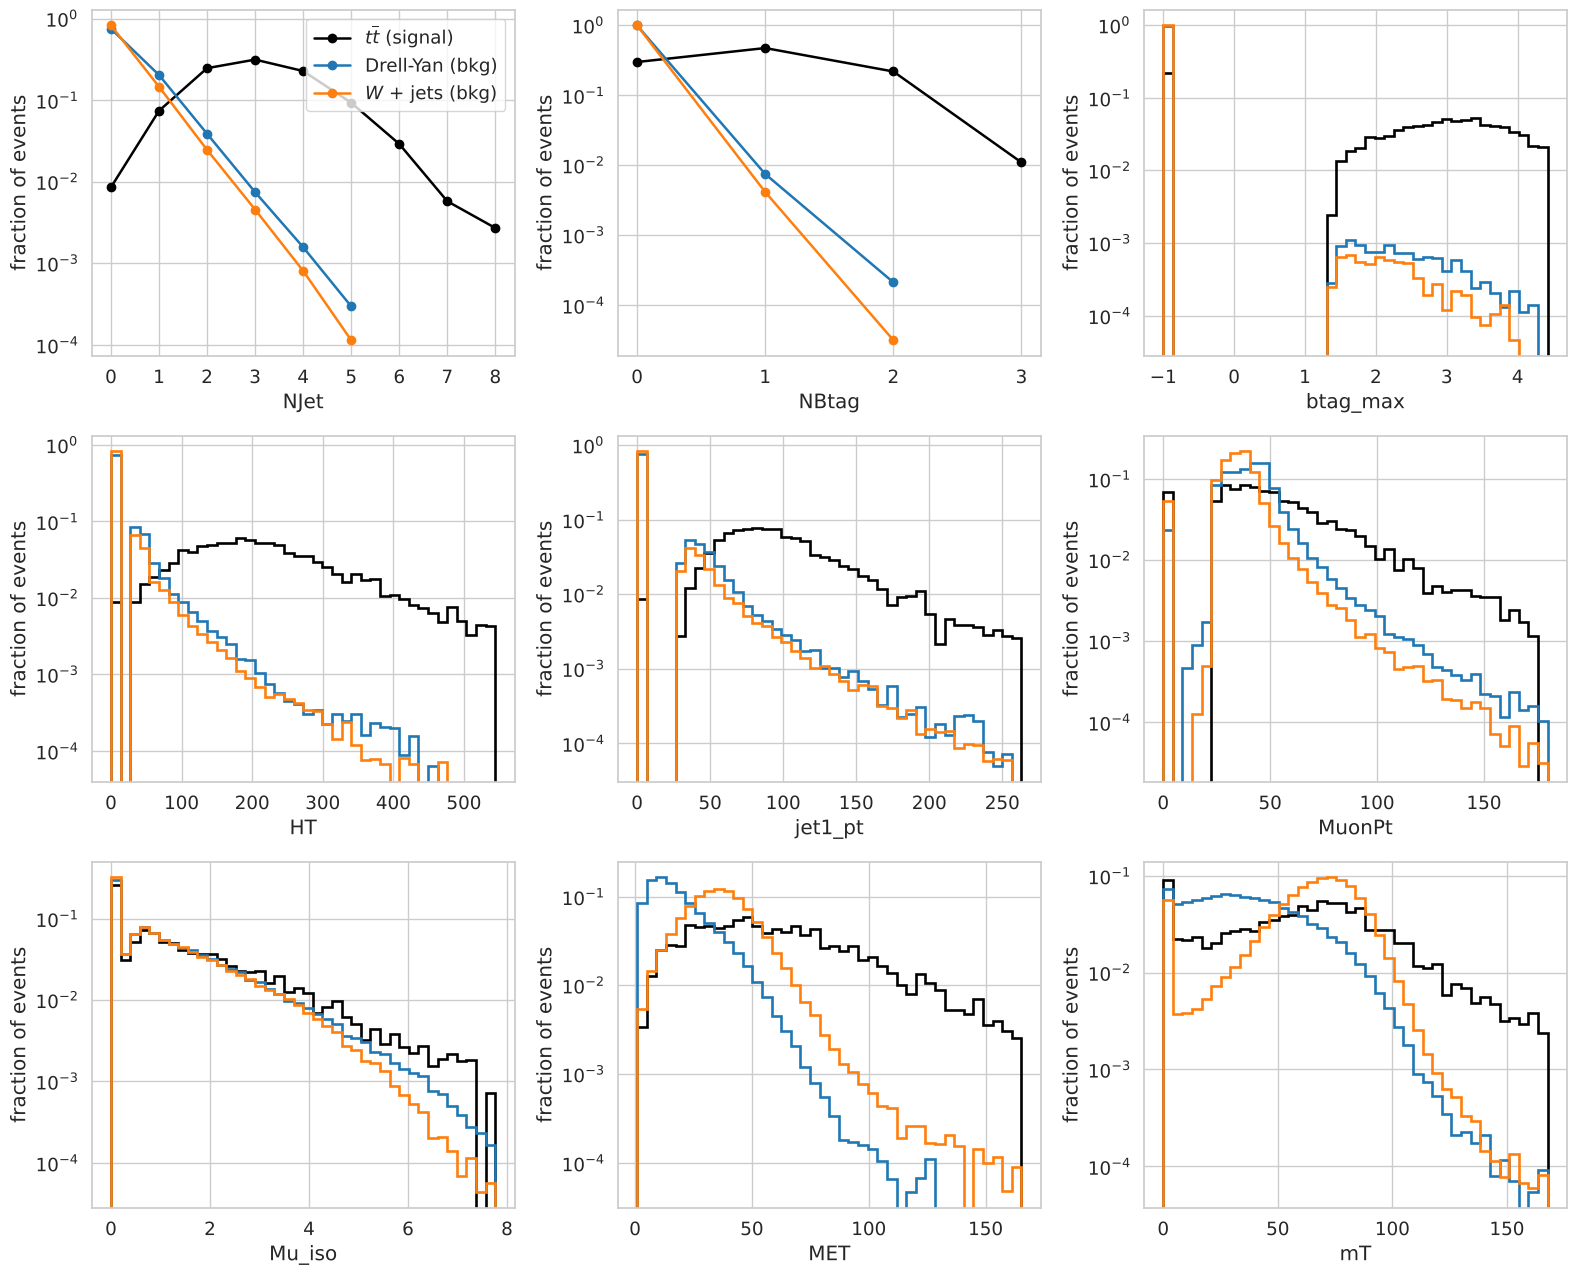

In [10]:
VARS_DIST = ['NJet', 'NBtag', 'btag_max', 'HT', 'jet1_pt', 'MuonPt', 'Mu_iso', 'MET', 'mT']
DISCRETAS = ['NJet', 'NBtag']

fig, axes = plt.subplots(3, 3, figsize=(16, 13))

for ax, var in zip(axes.ravel(), VARS_DIST):
    todos = np.concatenate([d[var].to_numpy() for d, _, _ in samples])
    if var in DISCRETAS:
        bordas = np.arange(todos.min() - 0.5, todos.max() + 1.5, 1)
    else:
        bordas = np.linspace(np.percentile(todos, 0.1), np.percentile(todos, 99.9), 41)
    centros = (bordas[:-1] + bordas[1:]) / 2

    for d, label, cor in samples:
        x, peso = d[var].to_numpy(), d['EventWeight'].to_numpy()
        contagem, _ = np.histogram(x, bins=bordas)
        h, _ = np.histogram(x, bins=bordas, weights=peso)
        h = np.where(contagem >= 5, h / h.sum(), np.nan)
        if var in DISCRETAS:
            ax.plot(centros, h, marker='o', color=cor, lw=1.8, label=label)
        else:
            ax.stairs(h, bordas, color=cor, lw=1.9, label=label)

    ax.set_yscale('log')
    ax.set_xlabel(var)
    ax.set_ylabel('fraction of events')
    if var in DISCRETAS:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))

axes[0, 0].legend(frameon=True, loc='upper right')
plt.tight_layout()
plt.show()

As distribuições normalizadas mostram onde cada processo se concentra. O sinal $t\bar t$ se desloca para mais jets (`NJet`), mais jets com b-tag (`NBtag`) e maior $H_T$, enquanto Drell–Yan e $W$+jets concentram a maior parte dos eventos em poucos jets e sem b-tag. `NMuon` ajuda principalmente a separar o Drell–Yan, que costuma ter dois múons. Há sobreposição em todas as variáveis, e nenhuma delas separa as classes sozinha. Variáveis discretas são desenhadas com marcadores, e bins com menos de 5 eventos simulados são omitidos.

### Momento transversal faltante

O momento transversal faltante representa o desbalanço de momento no plano perpendicular ao feixe. Suas duas componentes aparecem no conjunto de entrada como `MET_px` e `MET_py`, e o módulo,

$$
|\mathrm{MET}| =
\sqrt{\mathrm{MET}_{px}^2+\mathrm{MET}_{py}^2},
$$

como `MET`. Os gráficos abaixo mostram o módulo (normalizado como acima) e o plano das duas componentes, em escala de cor comum aos três painéis.

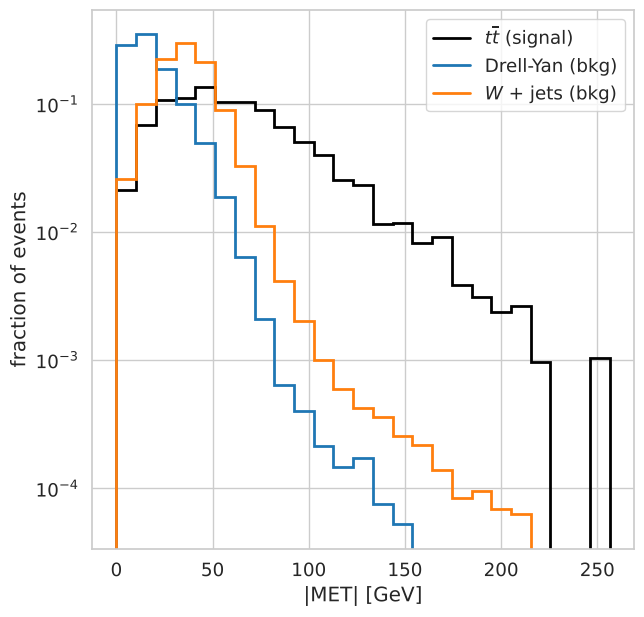

In [11]:
bins = np.linspace(0, 400, 40)
centros = (bins[:-1] + bins[1:]) / 2

fig, ax = plt.subplots(figsize=(7, 7))
for d, label, cor in samples:
    contagem, _ = np.histogram(d['MET'], bins=bins)
    h, _ = np.histogram(d['MET'], bins=bins, weights=d['EventWeight'])
    ax.stairs(np.where(contagem >= 5, h / h.sum(), np.nan), bins, color=cor, lw=2, label=label)

ax.set_yscale('log')
ax.set_xlabel(r'$|$MET$|$ [GeV]')
ax.set_ylabel('fraction of events')
ax.legend(frameon=True)
plt.show()

In [12]:
edges = np.linspace(-150, 150, 41)
centers = (edges[:-1] + edges[1:]) / 2
titles = [label.replace(r'$t\overline{t}$', 'tt\u0304').replace('$W$', 'W') for _, label, _ in samples]

dens = []
for d, _, _ in samples:
    contagem, _, _ = np.histogram2d(d['MET_px'], d['MET_py'], bins=[edges, edges], weights=d['EventWeight'])
    dens.append(contagem / contagem.sum())

zmax = max(np.log10(m[m > 0]).max() for m in dens)
zmin = min(np.log10(m[m > 0]).min() for m in dens)

fig = make_subplots(rows=1, cols=3, subplot_titles=titles, shared_yaxes=True, horizontal_spacing=0.03)

for col, m in enumerate(dens, start=1):
    z = np.where(m > 0, np.log10(np.where(m > 0, m, 1)), np.nan)
    fig.add_trace(
        go.Heatmap(
            x=centers, y=centers, z=z.T, zmin=zmin, zmax=zmax, colorscale='Greys',
            showscale=(col == 3), colorbar=dict(title='log10 (fraction of events per bin)'),
            hovertemplate='MET_px: %{x:.0f}<br>MET_py: %{y:.0f}<br>log10 fraction: %{z:.2f}<extra></extra>',
        ),
        row=1, col=col,
    )
    fig.update_xaxes(title_text='MET_px', tickvals=[-100, 0, 100], row=1, col=col)

fig.update_yaxes(title_text='MET_py', row=1, col=1)
fig.update_layout(width=1150, height=420)
fig.show()

In [13]:

medias_met = {rotulo: float(np.average(np.hypot(d["MET_px"], d["MET_py"]), weights=d["EventWeight"])) for d, rotulo, _ in samples}
linhas_met = "; ".join(f"{rotulo}: {fmt(v)} GeV" for rotulo, v in medias_met.items())
display(Markdown(f"""Médias ponderadas de $|\\mathrm{{MET}}|$ por amostra: {linhas_met}.

Sinal e $W$+jets contêm neutrinos no estado final, o que gera um desbalanço transversal real. Drell–Yan com dois múons não tem esse desbalanço, e seu MET reflete sobretudo resolução do detector. Por isso o plano $(\\mathrm{{MET}}_x, \\mathrm{{MET}}_y)$ do Drell–Yan fica mais concentrado em torno da origem. A distribuição é aproximadamente simétrica em torno da origem, e a informação útil está no módulo, que a rede recebe como variável `MET`."""))

Médias ponderadas de $|\mathrm{MET}|$ por amostra: $t\overline{t}$ (signal): 64,8 GeV; Drell-Yan (bkg): 19,3 GeV; $W$ + jets (bkg): 36,9 GeV.

Sinal e $W$+jets contêm neutrinos no estado final, o que gera um desbalanço transversal real. Drell–Yan com dois múons não tem esse desbalanço, e seu MET reflete sobretudo resolução do detector. Por isso o plano $(\mathrm{MET}_x, \mathrm{MET}_y)$ do Drell–Yan fica mais concentrado em torno da origem. A distribuição é aproximadamente simétrica em torno da origem, e a informação útil está no módulo, que a rede recebe como variável `MET`.

## 6. Construção do conjunto de dados

A classificação será binária e supervisionada.

`X` reúne as 42 variáveis de entrada, `y` guarda a classe verdadeira e `w` guarda `EventWeight`. O rótulo 1 identifica $t\bar t$ e o rótulo 0 identifica Drell–Yan e $W$+jets.

`df_full` mantém todas as colunas carregadas dos arquivos, nas unidades originais, e será usado posteriormente para recuperar informações dos eventos selecionados.

Algumas variáveis têm cauda longa e valores positivos, como momentos transversais, massas e $H_T$. Para elas, `X` usa $\ln(1+x)$ em vez de $x$: a transformação comprime a cauda e aproxima a escala das demais variáveis, o que facilita o ajuste tanto da rede quanto dos modelos de referência. Ela é aplicada a cada evento separadamente, sem usar parâmetros estimados nos dados, e portanto não depende da divisão entre treino e teste.

In [14]:
LOG_COLS = ['HT', 'MuonPt', 'MET', 'ST', 'm_jets', 'm_mumu', 'ElePt', 'PhoPt', 'mT'] + [f'jet{i}_pt' for i in range(1, 7)]

df_full = pd.concat((ttbar, dy, wj), ignore_index=True)

df = df_full[variaveis].copy()          # unidades originais
X_log = df.copy()
X_log[LOG_COLS] = np.log1p(X_log[LOG_COLS].clip(lower=0))

X_log.head()

,NJet,NMuon,NElectron,NPhoton,MET_px,MET_py,MET,HT,NBtag,NJet30,...,dphi_mu_MET,m_mumu,dR_mu_jet,ElePt,PhoPt,ST,m_jets,mjj_W,m3j_top,m3j_maxpt
0,3.0,1.0,0.0,0.0,20.238705,1.876128,3.059902,4.967523,1.0,3.0,...,2.885015,0.0,1.155063,0.0,0.0,5.290937,4.991734,2.515030,26.308502,146.191498
1,5.0,1.0,0.0,0.0,-29.892015,16.498444,3.559420,6.328690,1.0,5.0,...,2.942663,0.0,0.829049,0.0,0.0,6.477194,6.877163,46.189507,102.861450,591.449707
2,5.0,1.0,0.0,0.0,-24.056999,-46.160618,3.971296,5.780723,0.0,5.0,...,2.056588,0.0,1.415704,0.0,0.0,5.996717,5.910523,1.625572,8.491180,139.396927
3,3.0,1.0,0.0,0.0,-30.039965,5.851555,3.453302,5.532857,2.0,3.0,...,1.029611,0.0,0.744691,0.0,0.0,5.780717,5.554925,32.125591,85.007538,257.507538
4,3.0,1.0,0.0,0.0,4.518302,117.570068,4.776236,5.362707,1.0,3.0,...,1.663794,0.0,1.722953,0.0,0.0,6.001891,5.569835,45.481293,88.890717,261.390717


In [15]:
X = X_log.values
X.shape

(191981, 42)

In [16]:
w = df_full['EventWeight'].values

Os rótulos são construídos na mesma ordem usada na concatenação das amostras: primeiro $t\bar t$, depois Drell–Yan e, por fim, $W$+jets.

In [17]:
sample_labels = [(ttbar, 1), (dy, 0), (wj, 0)]   # 1 = sinal, 0 = background
y = np.concatenate([np.full(len(sample), label) for sample, label in sample_labels])

pd.Series(y).value_counts()

0    187466
1      4515
Name: count, dtype: int64

## 7. Desbalanceamento das classes

A quantidade de eventos de sinal é muito menor que a quantidade de eventos de background. Observamos esse desbalanceamento tanto pela contagem dos eventos quanto pela soma de `EventWeight`.

A contagem determina quantos exemplos de cada classe chegam ao treinamento. `EventWeight` entra na ponderação das distribuições e métricas. Durante o treinamento, `class_weight` será usado para aumentar a contribuição da classe menos frequente na função de custo.

In [18]:
counts = pd.DataFrame(
    {'background': [(y == 0).sum(), w[y == 0].sum()],
     'sinal': [(y == 1).sum(), w[y == 1].sum()]},
    index=['eventos', 'soma de EventWeight'],
)
counts['background / sinal'] = counts['background'] / counts['sinal']

counts.round(1)

,background,sinal,background / sinal
eventos,187466.0,4515.0,41.5
soma de EventWeight,243719.1,1001.8,243.3


In [19]:
float((y == 0).mean())   # acurácia de um classificador que responde sempre "background"

0.9764820477026372

O background é ≈ 42 vezes mais numeroso em eventos simulados e tem soma de `EventWeight` ≈ 243 vezes maior que a do sinal. Por isso a **acurácia isolada é enganosa**: um classificador que responde sempre "background" acerta ≈ 97,6% dos eventos sem selecionar nenhum sinal. A avaliação final usará eficiência de sinal, eficiência de background, rejeição, a curva de eficiências e a pureza.

## 8. Divisão entre treino e teste

`train_test_split` separa os eventos usados no ajuste da rede dos eventos reservados para a avaliação final. A divisão é realizada simultaneamente para `X`, `y`, `w` e `ix`, preservando a correspondência entre variáveis, rótulos, pesos e índices originais.

Os índices em `ix` serão usados mais adiante para recuperar em `df_full` os eventos selecionados pelo classificador.

In [20]:
ix = np.arange(X.shape[0])

X_train, X_test, y_train, y_test, w_train, w_test, ix_train, ix_test = train_test_split(
    X, y, w, ix, train_size=0.6, random_state=SEED
)

X_train.shape, X_test.shape

((115188, 42), (76793, 42))

### Padronização das variáveis

`StandardScaler` transforma cada variável segundo

$$
z=\frac{x-\mu}{\sigma}.
$$

A média $\mu$ e o desvio-padrão $\sigma$ são calculados com `X_train`. A mesma transformação é aplicada a `X_test`. Dessa forma, a preparação do conjunto de teste usa exclusivamente os parâmetros obtidos no treinamento.

In [21]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 9. O Keras

A rede deste notebook é construída, treinada e avaliada com o **Keras**. Antes de montar a arquitetura, esta seção apresenta a biblioteca e mostra quais partes dela aparecem daqui em diante.

### O que é o Keras

O Keras é uma biblioteca de aprendizado profundo para Python com interface de alto nível: o usuário descreve camadas, função de custo e otimizador, e a biblioteca cuida do cálculo dos gradientes e da execução do treinamento. Tem como autor principal François Chollet, e sua primeira versão é de março de 2015.

O Keras 3 é uma reescrita completa da biblioteca e é **multi-backend**: o mesmo código pode rodar sobre TensorFlow, JAX ou PyTorch (o backend OpenVINO é apenas para inferência). O backend é escolhido antes de importar a biblioteca, pela variável de ambiente `KERAS_BACKEND` ou pelo arquivo `~/.keras/keras.json`. A célula a seguir mostra a versão e o backend em uso.

In [22]:
print('Keras', keras.__version__)
print('backend:', keras.backend.backend())

Keras 3.15.1
backend: tensorflow


### O que usamos do Keras

A tabela lista os componentes do Keras utilizados neste notebook e onde cada um aparece.

| Componente | Para que serve | Onde aparece |
|---|---|---|
| `keras.utils.set_random_seed` | fixa as sementes de Python, NumPy e do backend, para que o treinamento seja reprodutível | configuração inicial e antes de cada treinamento |
| `Input` | define a forma dos dados de entrada (42 variáveis por evento) | Arquitetura |
| `Dense` | camada totalmente conectada: combina as entradas e aplica uma ativação (`relu` ou `sigmoid`) | Arquitetura |
| `Dropout` | regularização: desativa unidades aleatoriamente durante o treinamento | Arquitetura |
| `Model` | liga entradas e saídas em um modelo; `summary()` lista camadas e parâmetros | Arquitetura |
| `compile` | define otimizador (`Adam`), função de custo (`binary_crossentropy`) e métricas | Compilação |
| `fit` | executa o treinamento, com `epochs`, `batch_size`, `class_weight`, `validation_data` e `callbacks` | Treinamento |
| `EarlyStopping`, `ReduceLROnPlateau` | callbacks que interrompem o treinamento e reduzem a taxa de aprendizado quando a validação deixa de melhorar | Treinamento |
| `save_weights`, `to_json` | salvam pesos e arquitetura | Treinamento |
| `predict` | calcula o score de cada evento | Predição |

### Como um modelo é construído e usado

O trabalho com o Keras segue um ciclo de cinco passos:

1. **definir** as camadas e ligá-las em um `Model`;
2. **compilar**, escolhendo otimizador, função de custo e métricas;
3. **treinar** com `fit`, passando os dados e os parâmetros de treinamento;
4. **prever** com `predict`;
5. **salvar** pesos e arquitetura para reutilizar o modelo.

O Keras oferece duas formas principais de definir um modelo. `Sequential` empilha camadas em sequência linear. A **API funcional**, usada aqui, chama cada camada sobre a saída da anterior (`Dense(64)(inputs)`), o que descreve o mesmo tipo de rede e também permite ramificações e várias entradas.

### Parâmetros que afetam o resultado e a eficiência

Alguns argumentos do Keras controlam quão bem e quão rápido a rede aprende. Eles aparecem ao longo do notebook e são testados, um de cada vez, na seção *Parâmetros do Keras e eficiência*.

| Parâmetro | Onde é definido | Efeito |
|---|---|---|
| `batch_size` | `fit` | número de eventos por atualização dos pesos. Lotes grandes reduzem o número de atualizações por época e o tempo de treinamento; lotes pequenos fazem mais atualizações, com mais ruído |
| `learning_rate` | otimizador (`Adam`) | tamanho do passo de cada atualização. Valores altos podem desestabilizar o treinamento; valores baixos tornam a convergência lenta |
| `epochs`, `patience` | `fit`, `EarlyStopping` | quanto treinar e quando parar |
| `rate` | `Dropout` | fração de unidades desativadas durante o treinamento (regularização) |
| `units` | `Dense` | número de neurônios da camada, que define a capacidade da rede |
| `class_weight` | `fit` | peso de cada classe na função de custo, para compensar o desbalanceamento |
| `ReduceLROnPlateau` | callback | reduz a taxa de aprendizado quando a `val_loss` deixa de melhorar |

### Outros recursos do Keras

O Keras tem outros recursos que se aplicam a problemas como este e que não são necessários aqui:

* **camadas de pré-processamento**, como `Normalization`, que incorpora ao próprio modelo a padronização feita aqui com `StandardScaler`;
* **métricas próprias**, como `keras.metrics.AUC`, calculadas durante o treinamento;
* **callbacks adicionais**, como `TensorBoard` e `CSVLogger`, para acompanhar e registrar o treinamento;
* **KerasTuner**, biblioteca complementar para busca automática de hiperparâmetros;
* **execução em GPU e TPU**, conforme o backend utilizado.

Documentação: <https://keras.io>.

## 10. Arquitetura da rede neural

A rede recebe as 42 variáveis de entrada. Cada camada `Dense` forma combinações das saídas da camada anterior, e a ativação `relu` introduz não linearidade nessas combinações.

Após cada camada densa, `Dropout(0.3)` desativa aleatoriamente 30% das unidades durante o treinamento. Esse mecanismo atua como regularização, importante aqui porque o conjunto de treino tem poucos eventos de sinal.

A última camada possui um neurônio com ativação `sigmoid`. Sua saída é um score entre 0 e 1 associado à classe sinal.

A arquitetura utilizada é

$$
42 \rightarrow 64 \rightarrow 32 \rightarrow 1.
$$

As larguras (64 e 32) e o `Dropout` de 0,3 foram escolhidos por validação cruzada dentro do conjunto de treino, entre 12 configurações com larguras de 10 a 128 neurônios, `Dropout` de 0,1 a 0,5, regularização L2 e normalização em lote. O conjunto de teste não participou dessa escolha. Redes maiores não ajudaram: com poucos eventos de sinal para treinar, elas passam a ajustar o ruído do treino.

In [23]:
inputs = Input(shape=(X_train.shape[1],))

hidden = Dense(64, activation='relu')(inputs)
hidden = Dropout(0.3)(hidden)

hidden = Dense(32, activation='relu')(hidden)
hidden = Dropout(0.3)(hidden)

outputs = Dense(1, activation='sigmoid')(hidden)

model = Model(inputs, outputs)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 42)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,865 (19.00 KB)

 Trainable params: 4,865 (19.00 KB)

 Non-trainable params: 0 (0.00 B)

A arquitetura possui 4865 parâmetros treináveis distribuídos entre as camadas densas. As camadas de `Dropout` atuam durante o treinamento sem introduzir novos parâmetros.

## 11. Compilação do modelo

A função de custo escolhida é `binary_crossentropy`, adequada a uma classificação binária com saída sigmoid:

$$
L=-\left[y\ln(\hat y)+(1-y)\ln(1-\hat y)\right].
$$

O otimizador `Adam`, com taxa de aprendizado de $10^{-3}$, atualiza os parâmetros da rede buscando reduzir essa função de custo. `accuracy` é registrada durante o treinamento como uma métrica complementar de acompanhamento.

In [24]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])

## 12. Treinamento

### Peso das classes

O conjunto de treino contém muito mais exemplos de background do que de sinal. `class_weight` aumenta a contribuição da classe menos frequente na função de custo durante o treinamento.

Os pesos são calculados a partir da contagem de `y_train`. `EventWeight` é usado na ponderação das distribuições e das métricas da análise.

In [25]:
class_weight = {
    label: float(0.5 * len(y_train) / (y_train == label).sum())
    for label in (0, 1)
}

class_weight

{0: 0.5119102641589931, 1: 21.490298507462686}

### Validação cruzada e ensemble

Treinar uma única rede dá um resultado que depende da inicialização e do conjunto particular usado como validação. Para reduzir essa dependência, o conjunto de treino é dividido em 5 partes (`StratifiedKFold`, que preserva a proporção de sinal em cada parte). Em cada rodada, uma rede é treinada com 4 partes e validada na quinta, e o score final de um evento é a **média das 5 redes**. A média (um *ensemble*) é mais estável que qualquer rede isolada.

A parte de validação é usada apenas para decidir quando parar. Dois *callbacks* controlam o treinamento:

* `EarlyStopping` monitora `val_loss`, encerra o ajuste após 8 épocas sem melhora e devolve à rede os pesos da melhor época;
* `ReduceLROnPlateau` reduz a taxa de aprendizado à metade quando a `val_loss` fica 4 épocas sem melhorar.

A função `construir_modelo` repete a arquitetura das seções anteriores e permite variar seus parâmetros, o que será usado nos testes de parâmetros mais adiante. Como cada evento fica fora do treino de exatamente uma das 5 redes, as previsões dessa rede para ele (`score_val`) são previsões de validação, que serão usadas para escolher o limiar de decisão sem tocar no conjunto de teste.

In [26]:
def construir_modelo(n_entradas, unidades=(64, 32), dropout=0.3, taxa=1e-3, l2=0.0):
    entrada = Input(shape=(n_entradas,))
    h = entrada
    for u in unidades:
        h = Dense(u, activation='relu', kernel_regularizer=keras.regularizers.l2(l2) if l2 else None)(h)
        if dropout > 0:
            h = Dropout(dropout)(h)
    m = Model(entrada, Dense(1, activation='sigmoid')(h))
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=taxa), loss='binary_crossentropy', metrics=['accuracy'])
    return m


def treinar_rede(X_ajuste, y_ajuste, X_valid, y_valid, semente, batch_size=256, usar_class_weight=True,
                 plateau=True, **arquitetura):
    keras.utils.set_random_seed(semente)
    rede = construir_modelo(X_ajuste.shape[1], **arquitetura)
    callbacks = [EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)]
    if plateau:
        callbacks.append(ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4))
    hist = rede.fit(
        X_ajuste, y_ajuste,
        class_weight=class_weight if usar_class_weight else None,
        validation_data=(X_valid, y_valid),
        epochs=80, batch_size=batch_size, callbacks=callbacks, verbose=0,
    )
    return rede, hist


construir_modelo(X_train.shape[1]).count_params()

4865

In [27]:
N_DOBRAS = 5
modelos, historicos = [], []
score_val = np.zeros(len(y_train))        # previsão de cada evento de treino pela rede que não o viu

dobras = StratifiedKFold(N_DOBRAS, shuffle=True, random_state=SEED).split(X_train, y_train)
for k, (i_ajuste, i_valid) in enumerate(dobras):
    rede, hist = treinar_rede(X_train[i_ajuste], y_train[i_ajuste], X_train[i_valid], y_train[i_valid], semente=SEED + k)
    rede.save_weights(MODELS / f'ttbar_fold{k}.weights.h5')
    score_val[i_valid] = rede.predict(X_train[i_valid], batch_size=2048, verbose=0).ravel()
    modelos.append(rede)
    historicos.append(hist)
    print(f'rede {k + 1}/{N_DOBRAS}: {len(hist.history["loss"])} épocas, val_loss = {min(hist.history["val_loss"]):.4f}')

with open(MODELS / 'ttbar_rede.json', 'w') as f:
    f.write(modelos[0].to_json())

rede 1/5: 26 épocas, val_loss = 0.0665


rede 2/5: 14 épocas, val_loss = 0.0803


rede 3/5: 28 épocas, val_loss = 0.0624


rede 4/5: 17 épocas, val_loss = 0.0709


rede 5/5: 12 épocas, val_loss = 0.0680


In [28]:
def plot_history(history, acc_trivial):
    epochs = list(range(1, len(history.history['loss']) + 1))

    fig = make_subplots(rows=1, cols=2)
    for col, (metric, ylabel) in enumerate([('loss', 'loss'), ('accuracy', 'accuracy')], start=1):
        for name, key, color in [('training', metric, '#1f77b4'), ('validation', f'val_{metric}', '#ff7f0e')]:
            fig.add_trace(
                go.Scatter(x=epochs, y=history.history[key], name=name, legendgroup=name,
                           showlegend=(col == 1), line=dict(color=color)),
                row=1, col=col,
            )
        fig.update_xaxes(title_text='epoch', row=1, col=col)
        fig.update_yaxes(title_text=ylabel, row=1, col=col)

    fig.add_trace(go.Scatter(x=[1, len(epochs)], y=[acc_trivial, acc_trivial], mode='lines',
                             name='always answering "background"',
                             line=dict(color='#d62728', dash='dash')), row=1, col=2)
    fig.update_layout(width=1000, height=420, hovermode='x unified')
    fig.show()


acc_trivial = float((y_train == 0).mean())
plot_history(historicos[0], acc_trivial)

In [29]:

n_ep = [len(h.history["loss"]) for h in historicos]
vl = [min(h.history["val_loss"]) for h in historicos]
gap = [h.history["val_loss"][-1] - h.history["loss"][-1] for h in historicos]
display(Markdown(f"""O treinamento de cada uma das {len(historicos)} redes parou entre {min(n_ep)} e {max(n_ep)} épocas pelo `EarlyStopping`, com menor `val_loss` entre {fmt(min(vl), 4)} e {fmt(max(vl), 4)}. A diferença final entre `val_loss` e `loss` de treino fica entre {fmt(min(gap), 4)} e {fmt(max(gap), 4)}, valores pequenos e próximos de zero, sem sobreajuste relevante nas curvas (o `Dropout` e a parada antecipada o contêm).

A acurácia fica próxima da linha tracejada de acurácia trivial ({fmt(100 * acc_trivial, 2)}%, obtida respondendo sempre background). Em um problema tão desbalanceado, a acurácia quase não distingue um bom classificador de um trivial, e por isso as métricas das próximas seções são eficiências ponderadas."""))

O treinamento de cada uma das 5 redes parou entre 12 e 28 épocas pelo `EarlyStopping`, com menor `val_loss` entre 0,0624 e 0,0803. A diferença final entre `val_loss` e `loss` de treino fica entre -0,0060 e 0,0046, valores pequenos e próximos de zero, sem sobreajuste relevante nas curvas (o `Dropout` e a parada antecipada o contêm).

A acurácia fica próxima da linha tracejada de acurácia trivial (97,67%, obtida respondendo sempre background). Em um problema tão desbalanceado, a acurácia quase não distingue um bom classificador de um trivial, e por isso as métricas das próximas seções são eficiências ponderadas.

## 13. Predição no conjunto de teste

O score de um evento é a média das previsões das 5 redes: `predizer(X_test)` produz, para cada evento do conjunto de teste, um número entre 0 e 1. Valores maiores indicam maior compatibilidade com a classe $t\bar t$.

Esse score funciona como uma medida de ordenação dos eventos. Uma interpretação direta como probabilidade exigiria uma etapa adicional de calibração.

`yhat_cls` aplica um limiar de 0,5 ao score e produz a decisão binária usada nas métricas seguintes. O limiar 0,5 é o ponto de corte natural de uma saída sigmoid; a seção *Ponto de operação* mostra como escolher outro valor sem usar o conjunto de teste.

In [30]:
def predizer(X_novo):
    return np.mean([m.predict(X_novo, batch_size=2048, verbose=0).ravel() for m in modelos], axis=0)


yhat = predizer(X_test)
yhat_cls = (yhat > 0.5).astype(int)

### Distribuição do score

A distribuição de `yhat` mostra como sinal e background ocupam o intervalo entre 0 e 1. O limiar de 0,5 marca o ponto usado para converter o score em classe. Bins com menos de 5 eventos simulados são omitidos.

In [31]:
TT = 'tt\u0304'   # t com barra

bins = np.linspace(0, 1, 26)
score_colors = {f'{TT} (signal)': 'black', 'background': '#1f77b4'}

fig = go.Figure()
for label, name in [(1, f'{TT} (signal)'), (0, 'background')]:
    sel = y_test == label
    contagem, _ = np.histogram(yhat[sel], bins=bins)
    hist, _ = np.histogram(yhat[sel], bins=bins, weights=w_test[sel])
    hist = np.where(contagem >= 5, hist / hist.sum(), np.nan)

    fig.add_trace(go.Scatter(
        x=bins, y=np.r_[hist, hist[-1]], mode='lines', line_shape='hv', name=name,
        line=dict(width=2, color=score_colors[name]),
        hovertemplate='score: %{x:.3f}<br>fraction: %{y:.3e}<extra></extra>',
    ))

fig.add_vline(x=0.5, line_dash='dash', annotation_text='threshold = 0.5', annotation_position='top')
fig.update_layout(width=760, height=520, xaxis_title='network score', yaxis_title='fraction of events',
                  yaxis_type='log', yaxis_dtick=1, hovermode='x unified')
fig.show()

O sinal se concentra em scores altos e o background em scores baixos. A região de sobreposição reúne os eventos mais difíceis de separar.

A escala logarítmica permite observar também a pequena fração de background que alcança scores altos. Como o background possui contribuição ponderada muito maior, essa cauda tem impacto importante na pureza da seleção.

O limiar 0,5 representa um ponto de operação. Limiares maiores tornam a seleção mais restritiva; limiares menores preservam uma fração maior do sinal.

### Matriz de confusão

A matriz de confusão compara a classe verdadeira `y_test` com a classe prevista `yhat_cls`.

`sample_weight=w_test` incorpora `EventWeight` ao cálculo. Com `normalize='true'`, cada linha representa a fração ponderada de uma classe verdadeira que foi atribuída a cada classe prevista.

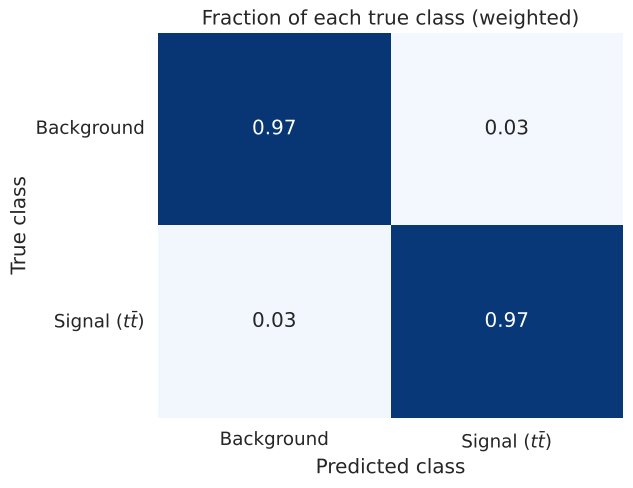

In [32]:
cnf_matrix = confusion_matrix(y_test, yhat_cls, sample_weight=w_test, normalize='true')
labels = ['Background', r'Signal ($t\bar{t}$)']

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cnf_matrix, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False,
            xticklabels=labels, yticklabels=labels, ax=ax)
ax.set(xlabel='Predicted class', ylabel='True class', title='Fraction of each true class (weighted)')
ax.tick_params(axis='y', rotation=0)
plt.show()

### Eficiência de sinal e background

A eficiência de sinal,

$$
\epsilon_S,
$$

é a fração ponderada dos eventos de $t\bar t$ classificados como sinal.

A eficiência de background,

$$
\epsilon_B,
$$

é a fração ponderada dos eventos de background classificados como sinal.

A rejeição de background é definida por

$$
\frac{1}{\epsilon_B}.
$$

In [33]:
def efficiency(label):
    selected = y_test == label
    return w_test[selected & (yhat_cls == 1)].sum() / w_test[selected].sum()


sig_eff = efficiency(1)
b_eff = efficiency(0)

pd.Series({'eficiência de sinal': sig_eff,
           'eficiência de background': b_eff,
           'rejeição de background': 1 / b_eff})

eficiência de sinal          0.966266
eficiência de background     0.025679
rejeição de background      38.942417
dtype: float32

### Eficiência de background em função da eficiência de sinal

Cada limiar de decisão produz um par formado pela eficiência de sinal (`tpr`) e pela eficiência de background (`fpr`).

O gráfico usa eficiência de sinal no eixo horizontal e eficiência de background no eixo vertical, com escala logarítmica. Essa forma destaca a região de baixa eficiência de background, que é especialmente relevante nesta análise.

A mesma informação pode ser apresentada na convenção ROC tradicional, com `fpr` no eixo horizontal e `tpr` no vertical. A AUC é calculada separadamente a partir dessa definição convencional.

In [34]:
fpr, tpr, thresholds = roc_curve(y_test, yhat, sample_weight=w_test)
idx = np.linspace(0, len(fpr) - 1, 2000).astype(int)

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=tpr[idx], y=fpr[idx], mode='lines', name='network (ensemble)', line=dict(color='black', width=2),
    customdata=np.clip(thresholds[idx], 0, 1),
    hovertemplate=('signal efficiency: %{x:.3f}<br>background efficiency: %{y:.2e}'
                   '<br>threshold: %{customdata:.3f}<extra></extra>'),
))
fig.add_trace(go.Scatter(
    x=[float(sig_eff)], y=[float(b_eff)], mode='markers', name='threshold = 0.5',
    marker=dict(color='#d62728', size=10),
))
fig.update_layout(
    width=700, height=650,
    xaxis=dict(range=[0.3, 1.0]),
    yaxis=dict(type='log', dtick=1, exponentformat='power', range=[-4.2, 0.1]),
    xaxis_title='signal efficiency (TPR)', yaxis_title='background efficiency (FPR)',
    legend=dict(x=0.02, y=0.98, xanchor='left', yanchor='top'),
)
fig.show()

In [35]:
auc = float(roc_auc_score(y_test, yhat, sample_weight=w_test))
auc

0.995794003253525

In [36]:
display(Markdown(f'''Nas saídas acima, a AUC é **{fmt(auc, 4)}**. Com limiar 0,5, a eficiência de sinal é **{fmt(100 * sig_eff)}%** e a eficiência de background é **{fmt(100 * b_eff, 2)}%**, correspondendo a uma rejeição de background de **{fmt(1 / b_eff, 0)}**.

A AUC resume a separação global produzida pelo score, mas fica muito próxima de 1 para qualquer modelo razoável e distingue pouco entre eles. Por isso, as comparações das próximas seções fixam a eficiência de sinal e comparam a eficiência de background. A curva de eficiências mostra como o ponto de operação muda com o limiar e permite escolher o compromisso desejado entre preservar sinal e rejeitar background.'''))

Nas saídas acima, a AUC é **0,9958**. Com limiar 0,5, a eficiência de sinal é **96,6%** e a eficiência de background é **2,57%**, correspondendo a uma rejeição de background de **39**.

A AUC resume a separação global produzida pelo score, mas fica muito próxima de 1 para qualquer modelo razoável e distingue pouco entre eles. Por isso, as comparações das próximas seções fixam a eficiência de sinal e comparam a eficiência de background. A curva de eficiências mostra como o ponto de operação muda com o limiar e permite escolher o compromisso desejado entre preservar sinal e rejeitar background.

## 14. Pureza da seleção

Depois da aplicação do limiar, `S` representa a contribuição ponderada dos eventos de sinal selecionados e `B` representa a contribuição ponderada dos backgrounds selecionados.

A pureza é definida como

$$
\mathrm{pureza}=\frac{S}{S+B}.
$$

Ela responde à pergunta: entre os eventos que passaram pela seleção de sinal, qual fração ponderada pertence de fato ao processo $t\bar t$?

In [37]:
S = w_test[(y_test == 1) & (yhat_cls == 1)].sum()
B = w_test[(y_test == 0) & (yhat_cls == 1)].sum()

pd.Series({'S': S, 'B': B, 'pureza S / (S + B)': S / (S + B)})

S                      391.575134
B                     2514.375000
pureza S / (S + B)       0.134749
dtype: float32

In [38]:
display(Markdown(f'''Nas saídas acima, a pureza com limiar 0,5 é **{fmt(100 * S / (S + B))}%**. A contribuição ponderada total do background é muito maior que a do sinal; por isso, uma eficiência de background de poucos por cento ainda deixa uma quantidade relevante de background na seleção.

Eficiência de sinal, eficiência de background e pureza descrevem aspectos complementares do mesmo ponto de operação. Um limiar mais restritivo pode reduzir a contaminação ao custo de perder parte do sinal.'''))

Nas saídas acima, a pureza com limiar 0,5 é **13,5%**. A contribuição ponderada total do background é muito maior que a do sinal; por isso, uma eficiência de background de poucos por cento ainda deixa uma quantidade relevante de background na seleção.

Eficiência de sinal, eficiência de background e pureza descrevem aspectos complementares do mesmo ponto de operação. Um limiar mais restritivo pode reduzir a contaminação ao custo de perder parte do sinal.

## 15. Eficiência da rede em pontos de operação fixos

O limiar 0,5 é apenas um ponto da curva ROC. Para descrever a rede em vários pontos, fixa-se a **eficiência de sinal** (ε$_S$) e calcula-se a eficiência de background (ε$_B$) correspondente e a pureza da seleção. Quanto menor o ε$_B$ para um mesmo ε$_S$, melhor a rejeição de background. Todas as quantidades usam `EventWeight` e o conjunto de teste.

As funções abaixo calculam essas grandezas e serão reutilizadas nas seções seguintes.

In [39]:
def eficiencias(selecionado):
    sinal = (y_test == 1) & selecionado
    fundo = (y_test == 0) & selecionado
    es = w_test[sinal].sum() / w_test[y_test == 1].sum()
    eb = w_test[fundo].sum() / w_test[y_test == 0].sum()
    return es, eb, w_test[sinal].sum() / (w_test[sinal].sum() + w_test[fundo].sum())


def eb_fixo(y_, score_, w_, es_alvo):
    """Eficiência de background quando a eficiência de sinal vale es_alvo."""
    fpr, tpr, _ = roc_curve(y_, score_, sample_weight=w_)
    return float(np.interp(es_alvo, tpr, fpr))


def eb_na_es(score, es_alvo):
    return eb_fixo(y_test, score, w_test, es_alvo)


def pureza_em(es, eb):
    S = es * w_test[y_test == 1].sum()
    B = eb * w_test[y_test == 0].sum()
    return float(S / (S + B))

In [40]:
alvos_es = [0.80, 0.90, 0.95]
linhas = {}
for es in alvos_es:
    eb = eb_na_es(yhat, es)
    linhas[f'ε_S = {int(100 * es)}%'] = {'ε_B (%)': 100 * eb, 'rejeição de background': 1 / eb,
                                         'pureza (%)': 100 * pureza_em(es, eb)}

pd.DataFrame(linhas).T.round(3)

,ε_B (%),rejeição de background,pureza (%)
ε_S = 80%,0.213,469.887,60.873
ε_S = 90%,0.551,181.531,40.340
ε_S = 95%,1.337,74.798,22.726


A eficiência de background nesses pontos é estimada com poucos eventos: em ε$_S$ = 90%, restam algumas centenas de eventos de background na seleção. Para quantificar essa incerteza, o conjunto de teste é reamostrado 300 vezes com reposição (*bootstrap*) e o ε$_B$ é recalculado em cada reamostragem. O intervalo entre os percentis 2,5% e 97,5% indica a faixa de variação esperada.

In [41]:
rng = np.random.default_rng(SEED)
reamostras = [rng.integers(0, len(y_test), len(y_test)) for _ in range(300)]

intervalos = {}
for es in alvos_es:
    valores = [100 * eb_fixo(y_test[i], yhat[i], w_test[i], es) for i in reamostras]
    intervalos[f'ε_S = {int(100 * es)}%'] = [100 * eb_na_es(yhat, es), np.percentile(valores, 2.5), np.percentile(valores, 97.5)]

tabela_boot = pd.DataFrame(intervalos, index=['ε_B (%)', 'IC 2,5%', 'IC 97,5%']).T
tabela_boot.round(3)

,ε_B (%),"IC 2,5%","IC 97,5%"
ε_S = 80%,0.213,0.170,0.261
ε_S = 90%,0.551,0.436,0.757
ε_S = 95%,1.337,1.084,1.900


In [42]:

frases = []
for nome, linha in tabela_boot.iterrows():
    frases.append(f"* **{nome}**: ε_B = {fmt(linha['ε_B (%)'], 3)}% (IC 95%: {fmt(linha['IC 2,5%'], 3)}% a {fmt(linha['IC 97,5%'], 3)}%), rejeição de background de cerca de {fmt(100 / linha['ε_B (%)'], 0)}.")
lista = chr(10).join(frases)
display(Markdown(f"""**Leitura da tabela.**

{lista}

Exigir mais sinal custa mais background: ao subir ε_S de 80% para 95%, o ε_B cresce cerca de {fmt(tabela_boot.loc['ε_S = 95%', 'ε_B (%)'] / tabela_boot.loc['ε_S = 80%', 'ε_B (%)'], 1)} vez(es). A pureza cai junto, porque o background total é muito maior que o sinal. Os intervalos de confiança mostram que o ε_B é conhecido com uma incerteza relativa de algumas dezenas de por cento, por causa do número limitado de eventos de background que sobram na seleção."""))

**Leitura da tabela.**

* **ε_S = 80%**: ε_B = 0,213% (IC 95%: 0,170% a 0,261%), rejeição de background de cerca de 470.
* **ε_S = 90%**: ε_B = 0,551% (IC 95%: 0,436% a 0,757%), rejeição de background de cerca de 182.
* **ε_S = 95%**: ε_B = 1,337% (IC 95%: 1,084% a 1,900%), rejeição de background de cerca de 75.

Exigir mais sinal custa mais background: ao subir ε_S de 80% para 95%, o ε_B cresce cerca de 6,3 vez(es). A pureza cai junto, porque o background total é muito maior que o sinal. Os intervalos de confiança mostram que o ε_B é conhecido com uma incerteza relativa de algumas dezenas de por cento, por causa do número limitado de eventos de background que sobram na seleção.

### Testes de corte

Antes de usar uma rede, um físico tentaria separar $t\bar t$ com cortes simples em variáveis interpretáveis. Aqui são testados 15 cenários, combinando um número mínimo de jets (`NJet ≥ 1` a `5`) com um número mínimo de jets b-tagged (`NBtag ≥ 0`, `1` ou `2`). Cada corte produz um único ponto de operação (ε$_S$, ε$_B$), calculado no conjunto de teste com `EventWeight`. Para comparar com a rede, cada ponto é desenhado sobre a curva ROC da rede, e a tabela traz o ε$_B$ que a rede atinge na mesma eficiência de sinal do corte.

In [43]:
df_teste = df.iloc[ix_test]      # variáveis em unidades originais, para aplicar os cortes

linhas_corte = []
for nb in (0, 1, 2):
    for nj in (1, 2, 3, 4, 5):
        sel = (df_teste['NJet'].values >= nj) & (df_teste['NBtag'].values >= nb)
        es, eb, pur = eficiencias(sel)
        linhas_corte.append({'corte': f'NJet ≥ {nj}' + (f' e NBtag ≥ {nb}' if nb else ''), 'NBtag mínimo': nb,
                             'ε_S (%)': 100 * es, 'ε_B corte (%)': 100 * eb, 'pureza corte (%)': 100 * pur,
                             'ε_B rede na mesma ε_S (%)': 100 * eb_na_es(yhat, es)})

tabela_cortes = pd.DataFrame(linhas_corte)
tabela_cortes['ε_B corte / ε_B rede'] = tabela_cortes['ε_B corte (%)'] / tabela_cortes['ε_B rede na mesma ε_S (%)']
tabela_cortes.drop(columns='NBtag mínimo').round(3)

,corte,ε_S (%),ε_B corte (%),pureza corte (%),ε_B rede na mesma ε_S (%),ε_B corte / ε_B rede
0,NJet ≥ 1,99.292000,18.546,2.168000,10.276,1.805
1,NJet ≥ 2,91.586998,3.259,10.420000,0.740,4.404
2,NJet ≥ 3,66.098000,0.602,31.240999,0.083,7.218
3,NJet ≥ 4,35.623001,0.086,63.182999,0.010,8.598
4,NJet ≥ 5,11.952000,0.009,84.455002,0.001,12.504
5,NJet ≥ 1 e NBtag ≥ 1,70.027000,0.473,37.993999,0.110,4.287
6,NJet ≥ 2 e NBtag ≥ 1,66.563004,0.193,58.765999,0.089,2.173
7,NJet ≥ 3 e NBtag ≥ 1,49.518002,0.076,73.037003,0.024,3.124
8,NJet ≥ 4 e NBtag ≥ 1,27.110001,0.016,87.186996,0.004,4.396
9,NJet ≥ 5 e NBtag ≥ 1,9.108000,0.001,97.288002,0.001,1.443


In [44]:
fpr_nn, tpr_nn, _ = roc_curve(y_test, yhat, sample_weight=w_test)
i_nn = np.linspace(0, len(fpr_nn) - 1, 2000).astype(int)

fig = go.Figure()
fig.add_trace(go.Scatter(x=tpr_nn[i_nn], y=fpr_nn[i_nn], mode='lines', name='network (ensemble)',
                         line=dict(color='black', width=2)))
estilo = {0: ('circle', '#1f77b4', 'no b-tag requirement'), 1: ('diamond', '#ff7f0e', 'NBtag ≥ 1'), 2: ('square', '#2ca02c', 'NBtag ≥ 2')}
for nb, (simbolo, cor, nome) in estilo.items():
    d = tabela_cortes[tabela_cortes['NBtag mínimo'] == nb]
    fig.add_trace(go.Scatter(
        x=d['ε_S (%)'] / 100, y=d['ε_B corte (%)'] / 100, mode='markers+text', name=f'cuts: {nome}',
        text=[c.split(' ')[2] for c in d['corte']], textposition='top center',
        marker=dict(symbol=simbolo, size=10, color=cor),
        hovertemplate='%{customdata}<br>signal efficiency: %{x:.3f}<br>background efficiency: %{y:.2e}<extra></extra>',
        customdata=d['corte']))
fig.add_trace(go.Scatter(x=[float(sig_eff)], y=[float(b_eff)], mode='markers', name='network (threshold 0.5)',
                         marker=dict(color='#d62728', size=11)))
fig.update_layout(width=760, height=640, xaxis=dict(range=[0, 1.02], title='signal efficiency'),
                  yaxis=dict(type='log', dtick=1, exponentformat='power', range=[-4.2, 0.1], title='background efficiency'),
                  legend=dict(x=0.02, y=0.02, xanchor='left', yanchor='bottom'))
fig.show()

In [45]:

ref = tabela_cortes[tabela_cortes["corte"] == "NJet ≥ 3 e NBtag ≥ 1"].iloc[0]
so_jets = tabela_cortes[tabela_cortes["corte"] == "NJet ≥ 3"].iloc[0]
mais_puro = tabela_cortes.loc[tabela_cortes["pureza corte (%)"].idxmax()]
fator_min = tabela_cortes["ε_B corte / ε_B rede"].min()
n_melhor = int((tabela_cortes["ε_B corte / ε_B rede"] > 1).sum())
frase_todos = (f"Em {n_melhor} dos {len(tabela_cortes)} cenários, a rede atinge ε_B menor que o corte na mesma eficiência de sinal; a menor razão entre o ε_B do corte e o da rede é {fmt(fator_min, 1)} e a maior é {fmt(tabela_cortes['ε_B corte / ε_B rede'].max(), 1)}.")
display(Markdown(f"""**Leitura dos cortes.** Os números sobre cada ponto do gráfico indicam o `NJet` mínimo. Exigir mais jets reduz o background, mas também o sinal, e exigir b-tag reduz o background ainda mais, ao custo de eficiência de sinal. O corte `NJet ≥ 3` mantém ε_S = {fmt(so_jets["ε_S (%)"])}% com ε_B = {fmt(so_jets["ε_B corte (%)"], 3)}%; acrescentar `NBtag ≥ 1` leva a ε_S = {fmt(ref["ε_S (%)"])}% e ε_B = {fmt(ref["ε_B corte (%)"], 3)}%, com pureza de {fmt(ref["pureza corte (%)"])}%. O corte de maior pureza é `{mais_puro["corte"]}`, com {fmt(mais_puro["pureza corte (%)"])}% de pureza e ε_S = {fmt(mais_puro["ε_S (%)"])}%.

{frase_todos} Isso mostra o que a rede ganha ao combinar muitas variáveis: um corte usa duas variáveis e um único ponto de operação, enquanto a rede percorre toda a curva ROC e permite escolher o ponto de operação depois."""))

**Leitura dos cortes.** Os números sobre cada ponto do gráfico indicam o `NJet` mínimo. Exigir mais jets reduz o background, mas também o sinal, e exigir b-tag reduz o background ainda mais, ao custo de eficiência de sinal. O corte `NJet ≥ 3` mantém ε_S = 66,1% com ε_B = 0,602%; acrescentar `NBtag ≥ 1` leva a ε_S = 49,5% e ε_B = 0,076%, com pureza de 73,0%. O corte de maior pureza é `NJet ≥ 4 e NBtag ≥ 2`, com 98,4% de pureza e ε_S = 10,8%.

Em 13 dos 15 cenários, a rede atinge ε_B menor que o corte na mesma eficiência de sinal; a menor razão entre o ε_B do corte e o da rede é 1,0 e a maior é 12,5. Isso mostra o que a rede ganha ao combinar muitas variáveis: um corte usa duas variáveis e um único ponto de operação, enquanto a rede percorre toda a curva ROC e permite escolher o ponto de operação depois.

## 16. Contribuição de cada grupo de variáveis

Qual parte da informação das 42 variáveis faz diferença? Para responder, a rede é treinada com as nove variáveis de resumo (`NJet`, `NMuon`, `NElectron`, `NPhoton`, `MET_px`, `MET_py`, `HT`, `NBtag` e `MuonPt`) e com essas nove acrescidas de um grupo de cada vez, e por fim com todas. Cada configuração é treinada com 3 sementes.

Em cada treinamento, 15% do conjunto de treino serve de validação e o conjunto de teste só é usado para medir o resultado. A figura mostra o ε$_B$ com ε$_S$ = 90% (menor é melhor).

In [46]:
RESUMO = ['NJet', 'NMuon', 'NElectron', 'NPhoton', 'MET_px', 'MET_py', 'HT', 'NBtag', 'MuonPt']
GRUPOS = {
    'b-tag scores': ['jet1_btag', 'jet2_btag', 'jet3_btag', 'jet4_btag', 'btag_max', 'btag_sum'],
    'muon': ['Mu_eta', 'Mu_iso', 'Mu_charge', 'mT', 'dphi_mu_MET', 'dR_mu_jet', 'm_mumu'],
    'jet kinematics': [f'jet{i}_pt' for i in range(1, 7)] + [f'jet{i}_eta' for i in range(1, 5)] + ['NJet30', 'NJet50'],
    'masses': ['m_jets', 'mjj_W', 'm3j_top', 'm3j_maxpt'],
    'MET, ST, e/γ': ['MET', 'ST', 'ElePt', 'PhoPt'],
}
assert sorted(RESUMO + sum(GRUPOS.values(), [])) == sorted(variaveis)

SEMENTES = [SEED, 1, 2]
ES_ALVO = 0.90
i_ajuste, i_valid = train_test_split(np.arange(len(y_train)), test_size=0.15, stratify=y_train, random_state=SEED)


def treinar_e_avaliar(colunas, semente, **ajustes):
    idx = [variaveis.index(c) for c in colunas]
    inicio = time.perf_counter()
    rede, hist = treinar_rede(X_train[np.ix_(i_ajuste, idx)], y_train[i_ajuste],
                              X_train[np.ix_(i_valid, idx)], y_train[i_valid], semente, **ajustes)
    tempo = time.perf_counter() - inicio
    score = rede.predict(X_test[:, idx], batch_size=2048, verbose=0).ravel()
    eb = eb_na_es(score, ES_ALVO)
    return {'AUC': float(roc_auc_score(y_test, score, sample_weight=w_test)), 'ε_B (%)': 100 * eb,
            'pureza (%)': 100 * pureza_em(ES_ALVO, eb), 'tempo (s)': tempo, 'épocas': len(hist.history['loss'])}


conjuntos = {'9 summary variables': RESUMO}
for nome, cols in GRUPOS.items():
    conjuntos[f'+ {nome}'] = RESUMO + cols
conjuntos['all 42 variables'] = variaveis

In [47]:
res_grupos = []
for nome, cols in conjuntos.items():
    idx = [variaveis.index(c) for c in cols]
    for semente in SEMENTES:
        res_grupos.append({'conjunto': nome, 'semente': semente, **treinar_e_avaliar(cols, semente)})

df_grupos = pd.DataFrame(res_grupos)
resumo_grupos = df_grupos.groupby('conjunto', sort=False).agg(
    rede=('ε_B (%)', 'mean'), desvio=('ε_B (%)', 'std'), AUC=('AUC', 'mean'), pureza=('pureza (%)', 'mean'))
resumo_grupos.columns = ['ε_B rede (%)', 'desvio entre sementes', 'AUC rede', 'pureza rede (%)']
resumo_grupos.round(3)

,ε_B rede (%),desvio entre sementes,AUC rede,pureza rede (%)
conjunto,,,,
9 summary variables,0.917,0.102,0.995,29.000
+ b-tag scores,0.814,0.105,0.995,31.544
+ muon,0.853,0.006,0.995,30.396
+ jet kinematics,0.822,0.015,0.995,31.183
+ masses,0.877,0.005,0.995,29.815
"+ MET, ST, e/γ",0.818,0.049,0.995,31.335
all 42 variables,0.589,0.011,0.995,38.732


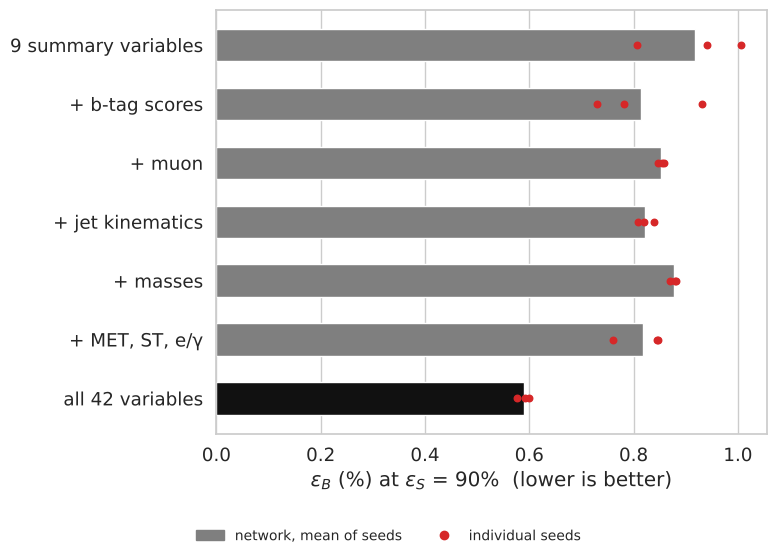

In [48]:
def grafico_configuracoes(df_res, coluna_grupo, painel_tempo=False, referencia='reference'):
    nomes = list(dict.fromkeys(df_res[coluna_grupo]))
    pos = np.arange(len(nomes))[::-1]
    fig, eixos = plt.subplots(1, 2 if painel_tempo else 1, figsize=(13 if painel_tempo else 8, 0.55 * len(nomes) + 1.8),
                              sharey=True, squeeze=False)
    a = eixos[0, 0]
    for nome, y_pos in zip(nomes, pos):
        d = df_res[df_res[coluna_grupo] == nome]
        cor = '#111111' if nome in (referencia, 'all 42 variables') else '#7f7f7f'
        a.barh(y_pos, d['ε_B (%)'].mean(), color=cor, height=0.55)
        a.scatter(d['ε_B (%)'], [y_pos] * len(d), color='#d62728', s=22, zorder=3)
        if painel_tempo:
            eixos[0, 1].barh(y_pos, d['tempo (s)'].mean(), color=cor, height=0.55)
    a.set_yticks(pos, nomes)
    a.set_xlabel(r'$\varepsilon_B$ (%) at $\varepsilon_S$ = 90%  (lower is better)')
    handles = [plt.Rectangle((0, 0), 1, 1, color='#7f7f7f'),
               plt.Line2D([], [], marker='o', color='#d62728', ls='', label='individual seeds')]
    rotulos = ['network, mean of seeds', 'individual seeds']
    eixos[0, 0].figure.legend(handles, rotulos, loc='lower center', ncol=len(rotulos), frameon=False, fontsize=10)
    if painel_tempo:
        eixos[0, 1].set_xlabel('training time (s)')
    for ax in eixos.ravel():
        ax.grid(axis='y', visible=False)
    plt.tight_layout(rect=(0, 0.07, 1, 1))
    plt.show()


grafico_configuracoes(df_grupos.rename(columns={'conjunto': 'configuração'}), 'configuração')

In [49]:

g = resumo_grupos
nome9, nome42 = "9 summary variables", "all 42 variables"
base_rede = g.loc[nome9, "ε_B rede (%)"]
fim_rede = g.loc[nome42, "ε_B rede (%)"]
ruido = float(g["desvio entre sementes"].mean())
mudancas = {n: g.loc[n, "ε_B rede (%)"] - base_rede for n in g.index if n.startswith("+")}
melhor = min(mudancas, key=mudancas.get)
lista_g = "; ".join(f"{n}: {'+' if v > 0 else ''}{fmt(v, 3)} p.p." for n, v in mudancas.items())
lista_g = lista_g.replace("p.p.", "p.p")
display(Markdown(f"""Com as 9 variáveis de resumo, a rede alcança ε_B = {fmt(base_rede, 3)}% em ε_S = 90%; com as 42 variáveis, {fmt(fim_rede, 3)}%, uma redução de fator {fmt(base_rede / fim_rede, 2)}. Isso mostra o quanto a informação adicional contida nas variáveis ajuda a rede a rejeitar background.

Mudança do ε_B da rede ao acrescentar cada grupo às 9 variáveis: {lista_g}. O desvio-padrão entre sementes é de cerca de {fmt(ruido, 3)} p.p. em média; mudanças menores que isso não devem ser lidas como efeito do grupo. O grupo com maior redução isolada foi **{melhor}**.

A barra escura marca a rede com todas as variáveis, que é a configuração usada no restante do notebook."""))

Com as 9 variáveis de resumo, a rede alcança ε_B = 0,917% em ε_S = 90%; com as 42 variáveis, 0,589%, uma redução de fator 1,56. Isso mostra o quanto a informação adicional contida nas variáveis ajuda a rede a rejeitar background.

Mudança do ε_B da rede ao acrescentar cada grupo às 9 variáveis: + b-tag scores: -0,103 p.p; + muon: -0,064 p.p; + jet kinematics: -0,095 p.p; + masses: -0,041 p.p; + MET, ST, e/γ: -0,100 p.p. O desvio-padrão entre sementes é de cerca de 0,042 p.p. em média; mudanças menores que isso não devem ser lidas como efeito do grupo. O grupo com maior redução isolada foi **+ b-tag scores**.

A barra escura marca a rede com todas as variáveis, que é a configuração usada no restante do notebook.

## 17. Ponto de operação

O limiar 0,5 é um ponto de operação entre muitos possíveis. Variar o limiar do score troca eficiência de sinal por pureza. A varredura abaixo calcula, para cada limiar, a eficiência de sinal, a eficiência de background e a pureza no conjunto de teste.

In [50]:
limiares = np.linspace(0.05, 0.99, 95)
varredura = pd.DataFrame(
    [eficiencias(yhat > t) for t in limiares],
    columns=['eficiência de sinal', 'eficiência de background', 'pureza'],
    index=pd.Index(limiares, name='limiar'),
)

fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.12,
                    subplot_titles=('Signal efficiency and purity', 'Background efficiency (dashed line: threshold 0.5)'))
fig.add_trace(go.Scatter(x=limiares, y=varredura['eficiência de sinal'], name='signal efficiency',
                         line=dict(color='black', width=2)), row=1, col=1)
fig.add_trace(go.Scatter(x=limiares, y=varredura['pureza'], name='purity',
                         line=dict(color='#d62728', width=2)), row=1, col=1)
fig.add_trace(go.Scatter(x=limiares, y=varredura['eficiência de background'], name='background efficiency',
                         line=dict(color='#1f77b4', width=2), showlegend=False), row=1, col=2)
for col in (1, 2):
    fig.add_vline(x=0.5, line_dash='dash', line_color='gray', row=1, col=col)
fig.update_yaxes(title_text='fraction', row=1, col=1)
fig.update_yaxes(type='log', dtick=1, exponentformat='power', title_text='fraction (log scale)', row=1, col=2)
fig.update_xaxes(title_text='score threshold')
fig.update_layout(width=1000, height=440, legend=dict(x=0.02, y=0.5, xanchor='left'))
fig.show()

In [51]:
alvos = [0.5, 0.7, 0.8, 0.9, 0.95]

pd.DataFrame(
    [eficiencias(yhat > t) for t in alvos],
    columns=['eficiência de sinal', 'eficiência de background', 'pureza'],
    index=pd.Index(alvos, name='limiar'),
).round(4)

,eficiência de sinal,eficiência de background,pureza
limiar,,,
0.50,0.9663,0.0257,0.1347
0.70,0.9511,0.0142,0.2166
0.80,0.9278,0.0090,0.3000
0.90,0.8942,0.0050,0.4248
0.95,0.8449,0.0031,0.5318


### Escolha do limiar sem usar o teste

Escolher o limiar olhando a tabela acima usaria o conjunto de teste para decidir, o que o torna otimista. Em vez disso, o limiar é definido com as previsões de validação (`score_val`), de eventos que cada rede não viu no treino: toma-se o valor do score em que a eficiência de sinal de validação é 90%. Esse limiar é então aplicado, sem ajuste, ao conjunto de teste.

In [52]:
fpr_v, tpr_v, thr_v = roc_curve(y_train, score_val, sample_weight=w_train)
limiar_escolhido = float(np.interp(0.90, tpr_v, thr_v))

es_t, eb_t, pur_t = eficiencias(yhat > limiar_escolhido)
es_v = w_train[(y_train == 1) & (score_val > limiar_escolhido)].sum() / w_train[y_train == 1].sum()
eb_v = w_train[(y_train == 0) & (score_val > limiar_escolhido)].sum() / w_train[y_train == 0].sum()

pd.DataFrame(
    {'validação': [es_v, eb_v], 'teste': [es_t, eb_t]},
    index=['eficiência de sinal', 'eficiência de background'],
).T.assign(limiar=limiar_escolhido).round(4)

,eficiência de sinal,eficiência de background,limiar
validação,0.8996,0.0069,0.8797
teste,0.9040,0.0061,0.8797


In [53]:

display(Markdown(f"""O limiar escolhido na validação foi **{fmt(limiar_escolhido, 3)}**. Na validação, ele produz ε_S = {fmt(100 * es_v)}% e ε_B = {fmt(100 * eb_v, 3)}%; no teste, ε_S = {fmt(100 * es_t)}% e ε_B = {fmt(100 * eb_t, 3)}%, com pureza de {fmt(100 * pur_t)}%. A eficiência de sinal no teste fica próxima do alvo de 90%, e a diferença entre validação e teste mostra a variação esperada de um limiar que não foi ajustado no teste. O limiar 0,5 fica em outro ponto da curva, com maior eficiência de sinal e maior contaminação; a escolha depende de quanto sinal se aceita perder para reduzir o background."""))

O limiar escolhido na validação foi **0,880**. Na validação, ele produz ε_S = 90,0% e ε_B = 0,694%; no teste, ε_S = 90,4% e ε_B = 0,611%, com pureza de 38,0%. A eficiência de sinal no teste fica próxima do alvo de 90%, e a diferença entre validação e teste mostra a variação esperada de um limiar que não foi ajustado no teste. O limiar 0,5 fica em outro ponto da curva, com maior eficiência de sinal e maior contaminação; a escolha depende de quanto sinal se aceita perder para reduzir o background.

## 18. Parâmetros do Keras e eficiência

Os parâmetros apresentados na seção do Keras controlam quão bem e quão rápido a rede aprende. Aqui eles são variados **um de cada vez**, a partir da configuração de referência: arquitetura 64-32, `Dropout` de 0,3, `Adam` com taxa $10^{-3}$, `batch_size` 256, `class_weight` balanceado e `ReduceLROnPlateau`, com `EarlyStopping` de paciência 8. Cada treinamento é feito com 85% do conjunto de treino e validado nos 15% restantes.

A eficiência é avaliada em dois sentidos:

* **separação**: eficiência de background (ε$_B$) quando a eficiência de sinal é fixada em 90%. Quanto menor o ε$_B$, melhor a rejeição de background. Fixar ε$_S$ torna comparáveis as configurações com e sem `class_weight`, já que o limiar 0,5 muda de significado quando o custo não é ponderado;
* **custo**: tempo de treinamento até o fim do `EarlyStopping`, medido nesta máquina.

Cada configuração é treinada com três sementes, e as tabelas mostram médias. O desvio-padrão do ε$_B$ entre sementes indica o tamanho do ruído: diferenças menores que ele não devem ser lidas como efeito do parâmetro. Esses testes descrevem a sensibilidade da rede aos parâmetros; a configuração de referência foi definida antes, por validação cruzada no conjunto de treino, e não por esta tabela. Para encurtar o tempo de execução, basta reduzir a lista `SEMENTES`.

In [54]:
configuracoes = {
    'reference': {},
    'batch_size 32': dict(batch_size=32),
    'batch_size 1024': dict(batch_size=1024),
    'learning rate 1e-2': dict(taxa=1e-2),
    'learning rate 1e-4': dict(taxa=1e-4),
    'dropout 0': dict(dropout=0.0),
    'dropout 0.5': dict(dropout=0.5),
    'L2 1e-4': dict(l2=1e-4),
    'network 10-20-30': dict(unidades=(10, 20, 30)),
    'network 128-64-32': dict(unidades=(128, 64, 32)),
    'no class_weight': dict(usar_class_weight=False),
    'no ReduceLROnPlateau': dict(plateau=False),
}

resultados = []
for semente in SEMENTES:
    for nome, ajuste in configuracoes.items():
        resultados.append({'configuração': nome, 'semente': semente, **treinar_e_avaliar(variaveis, semente, **ajuste)})

df_res = pd.DataFrame(resultados)

resumo = (
    df_res.groupby('configuração', sort=False)
    .agg(AUC=('AUC', 'mean'), eB=('ε_B (%)', 'mean'), eB_desvio=('ε_B (%)', 'std'),
         pureza=('pureza (%)', 'mean'), tempo=('tempo (s)', 'mean'), epocas=('épocas', 'mean'))
    .rename(columns={'eB': 'ε_B (%)', 'eB_desvio': 'desvio do ε_B', 'pureza': 'pureza (%)',
                     'tempo': 'tempo de treino (s)', 'epocas': 'épocas'})
)

resumo.round(3)

,AUC,ε_B (%),desvio do ε_B,pureza (%),tempo de treino (s),épocas
configuração,,,,,,
reference,0.995,0.589,0.011,38.732,78.604,46.667
batch_size 32,0.995,0.595,0.005,38.490,315.467,35.667
batch_size 1024,0.996,0.570,0.026,39.551,34.049,42.000
learning rate 1e-2,0.995,0.606,0.027,38.083,77.049,42.333
learning rate 1e-4,0.996,0.585,0.044,38.945,74.942,45.000
dropout 0,0.992,0.994,0.125,27.408,77.954,65.667
dropout 0.5,0.996,0.599,0.011,38.343,53.454,32.667
L2 1e-4,0.995,0.581,0.043,39.135,103.275,58.000
network 10-20-30,0.996,0.597,0.005,38.441,54.483,34.333


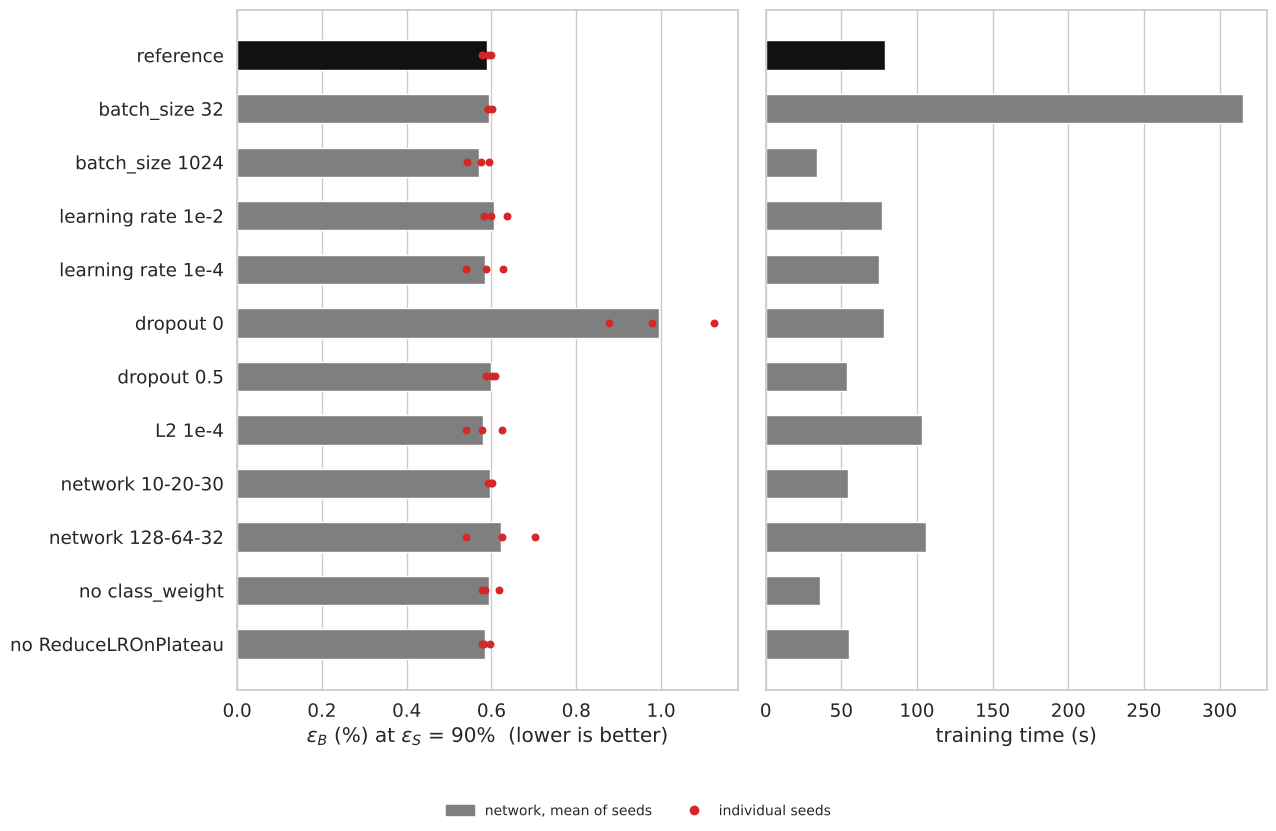

In [55]:
grafico_configuracoes(df_res, 'configuração', painel_tempo=True)

In [56]:

r = resumo
ref_eb = r.loc["reference", "ε_B (%)"]
ref_sd = r.loc["reference", "desvio do ε_B"]
dif = (r["ε_B (%)"] - ref_eb).drop("reference")
equiv = [n for n, v in dif.items() if abs(v) <= max(ref_sd, 1e-9) * 2]
piores = [n for n, v in dif.items() if v > 2 * ref_sd]
melhores = [n for n, v in dif.items() if v < -2 * ref_sd]
fmt_lista = lambda xs: ", ".join(xs) if xs else "nenhuma"
mais_rapida = r["tempo de treino (s)"].idxmin()
display(Markdown(f"""A configuração de referência tem ε_B = {fmt(ref_eb, 3)}% (desvio entre sementes {fmt(ref_sd, 3)}) e tempo de treino médio de {fmt(r.loc["reference", "tempo de treino (s)"], 0)} s. Tomando como critério uma diferença maior que dois desvios-padrão da referência:

* **equivalentes à referência**: {fmt_lista(equiv)};
* **piores**: {fmt_lista(piores)};
* **melhores**: {fmt_lista(melhores)}.

O treinamento mais rápido foi **{mais_rapida}**, com {fmt(r.loc[mais_rapida, "tempo de treino (s)"], 0)} s. Com apenas três sementes o desvio é ele mesmo incerto, então diferenças próximas do limite devem ser tratadas com cautela. A leitura geral é que a rede é pouco sensível à maioria dos parâmetros, e os que pioram o resultado de forma clara são os listados acima como piores, ligados à regularização e à capacidade da rede, o que é esperado com poucos eventos de sinal no treino. A configuração de referência foi escolhida por validação cruzada no treino, antes desta tabela, e permanece a configuração usada no restante do notebook."""))

A configuração de referência tem ε_B = 0,589% (desvio entre sementes 0,011) e tempo de treino médio de 79 s. Tomando como critério uma diferença maior que dois desvios-padrão da referência:

* **equivalentes à referência**: batch_size 32, batch_size 1024, learning rate 1e-2, learning rate 1e-4, dropout 0.5, L2 1e-4, network 10-20-30, no class_weight, no ReduceLROnPlateau;
* **piores**: dropout 0, network 128-64-32;
* **melhores**: nenhuma.

O treinamento mais rápido foi **batch_size 1024**, com 34 s. Com apenas três sementes o desvio é ele mesmo incerto, então diferenças próximas do limite devem ser tratadas com cautela. A leitura geral é que a rede é pouco sensível à maioria dos parâmetros, e os que pioram o resultado de forma clara são os listados acima como piores, ligados à regularização e à capacidade da rede, o que é esperado com poucos eventos de sinal no treino. A configuração de referência foi escolhida por validação cruzada no treino, antes desta tabela, e permanece a configuração usada no restante do notebook.

## 19. Análise dos falsos positivos

Os índices `ix_test` ligam as previsões do conjunto de teste aos eventos originais armazenados em `df_full`.

Com eles, recuperamos os eventos classificados como sinal e identificamos quais eram realmente $t\bar t$ e quais pertenciam aos backgrounds.

In [57]:
predicted_signal = df_full.iloc[ix_test[yhat_cls == 1]].copy()
predicted_signal['classe_verdadeira'] = np.where(y_test[yhat_cls == 1] == 1, 'sinal', 'background')

predicted_signal.head()

,NJet,NMuon,NElectron,NPhoton,MET_px,MET_py,MET,HT,NBtag,NJet30,...,ElePt,PhoPt,ST,m_jets,mjj_W,m3j_top,m3j_maxpt,triggerIsoMu24,EventWeight,classe_verdadeira
186441,1.0,1.0,0.0,0.0,27.874300,-82.358459,86.947639,92.546822,0.0,1.0,...,0.0,0.0,206.888413,4.255797,-1.000000,-1.000000,0.000000,True,2.342858,background
185864,1.0,1.0,0.0,0.0,75.562134,-33.901157,82.818626,108.774429,0.0,1.0,...,0.0,0.0,228.120312,23.144691,-1.000000,-1.000000,0.000000,True,2.581562,background
19897,3.0,1.0,0.0,0.0,4.526787,7.018157,8.351427,159.717377,0.0,3.0,...,0.0,0.0,211.276249,154.413101,20.574699,18.086899,154.413101,True,0.554355,background
2375,2.0,1.0,0.0,0.0,45.792496,2.434820,45.857182,129.801605,1.0,2.0,...,0.0,0.0,204.270429,133.901199,53.501198,-1.000000,0.000000,True,0.105165,sinal
3797,3.0,1.0,0.0,0.0,-46.432838,5.592508,46.768414,229.525940,1.0,3.0,...,0.0,0.0,312.859915,263.182526,18.322914,90.682526,263.182526,True,0.279545,sinal


A ordem usada em `df_full` permite reconstruir a amostra de origem de cada evento: $t\bar t$, Drell–Yan ou $W$+jets. Os falsos positivos são agrupados por essa origem e ponderados por `EventWeight`.

Em seguida, comparamos as médias ponderadas das variáveis entre o sinal selecionado e os backgrounds classificados como sinal. Para o momento transversal faltante usamos o módulo

$$
|\mathrm{MET}|=\sqrt{\mathrm{MET}_{p_x}^2+\mathrm{MET}_{p_y}^2},
$$

que representa a intensidade do desbalanço transversal.

In [58]:
n_tt, n_dy = ttbar.shape[0], dy.shape[0]
origem = np.select([ix_test < n_tt, ix_test < n_tt + n_dy], ['ttbar', 'dy'], default='wj')

fp = (y_test == 0) & (yhat_cls == 1)
pd.Series(w_test[fp]).groupby(origem[fp]).sum()

dy     318.259888
wj    2196.114990
dtype: float32

In [59]:
predicted_signal['MET'] = np.hypot(predicted_signal['MET_px'], predicted_signal['MET_py'])
features = ['NJet', 'NBtag', 'btag_max', 'HT', 'MET', 'mT', 'MuonPt', 'jet1_pt']

weighted_means = pd.DataFrame(
    {classe: [np.average(group[var], weights=group['EventWeight']) for var in features]
     for classe, group in predicted_signal.groupby('classe_verdadeira')},
    index=features,
).T

weighted_means

,NJet,NBtag,btag_max,HT,MET,mT,MuonPt,jet1_pt
background,1.949906,0.162230,-0.218803,140.285625,59.587549,62.325671,55.195929,90.14973
sinal,3.159135,0.964617,2.309441,236.784428,65.293164,65.082976,56.161891,106.69392


In [60]:
medias_amostras = pd.DataFrame(
    {nome: [np.average(d[var], weights=d['EventWeight']) for var in features]
     for nome, d in [('dy completo', dy), ('wj completo', wj)]},
    index=features,
).T

medias_amostras.round(2)

,NJet,NBtag,btag_max,HT,MET,mT,MuonPt,jet1_pt
dy completo,0.31,0.01,-0.96,16.67,19.31,37.36,41.90,13.74
wj completo,0.21,0.00,-0.98,11.51,36.91,63.80,35.74,9.66


In [61]:

fp_w = pd.Series(w_test[fp]).groupby(origem[fp]).sum()
fracao = fp_w / fp_w.sum()
fp_txt = "; ".join(f"{k}: {fmt(100 * v)}%" for k, v in fracao.items())
b_fp = weighted_means.loc["background"]
s_fp = weighted_means.loc["sinal"]
dy_m, wj_m = medias_amostras.loc["dy completo"], medias_amostras.loc["wj completo"]
display(Markdown(f"""Fração ponderada dos falsos positivos por origem: {fp_txt}.

Os backgrounds classificados como sinal estão muito mais próximos do sinal do que as amostras completas, embora ainda abaixo dele em `NJet` e $H_T$: `NJet` médio {fmt(b_fp["NJet"], 2)} (sinal selecionado {fmt(s_fp["NJet"], 2)}; `dy` completo {fmt(dy_m["NJet"], 2)}, `wj` completo {fmt(wj_m["NJet"], 2)}), $H_T$ médio {fmt(b_fp["HT"])} GeV (sinal {fmt(s_fp["HT"])} GeV), |MET| médio {fmt(b_fp["MET"])} GeV (sinal {fmt(s_fp["MET"])} GeV) e `MuonPt` médio {fmt(b_fp["MuonPt"])} GeV (sinal {fmt(s_fp["MuonPt"])} GeV).

A diferença que resta está nas variáveis de b-tag: `NBtag` médio {fmt(b_fp["NBtag"], 2)} nos falsos positivos contra {fmt(s_fp["NBtag"], 2)} no sinal, e `btag_max` médio {fmt(b_fp["btag_max"], 2)} contra {fmt(s_fp["btag_max"], 2)}. Isso é consistente com a leitura física de que o background mais difícil é $W$+jets com poucos jets e sem b-tag, que reproduz a topologia de um $t\\bar t$ em que parte dos jets não foi reconstruída. Para melhorar a separação nessa região seria necessário mais informação (por exemplo, reconstrução completa do decaimento) ou mais eventos simulados de sinal."""))

Fração ponderada dos falsos positivos por origem: dy: 12,7%; wj: 87,3%.

Os backgrounds classificados como sinal estão muito mais próximos do sinal do que as amostras completas, embora ainda abaixo dele em `NJet` e $H_T$: `NJet` médio 1,95 (sinal selecionado 3,16; `dy` completo 0,31, `wj` completo 0,21), $H_T$ médio 140,3 GeV (sinal 236,8 GeV), |MET| médio 59,6 GeV (sinal 65,3 GeV) e `MuonPt` médio 55,2 GeV (sinal 56,2 GeV).

A diferença que resta está nas variáveis de b-tag: `NBtag` médio 0,16 nos falsos positivos contra 0,96 no sinal, e `btag_max` médio -0,22 contra 2,31. Isso é consistente com a leitura física de que o background mais difícil é $W$+jets com poucos jets e sem b-tag, que reproduz a topologia de um $t\bar t$ em que parte dos jets não foi reconstruída. Para melhorar a separação nessa região seria necessário mais informação (por exemplo, reconstrução completa do decaimento) ou mais eventos simulados de sinal.

In [62]:

tb = tabela_boot
display(Markdown(f"""## 20. Conclusões

O problema é separar $t\\bar t$ de Drell–Yan e $W$+jets a partir de variáveis de eventos simulados do LHC, com forte desbalanceamento entre as classes e pesos de evento. A solução usa 42 variáveis calculadas a partir das saídas do detector, uma rede densa em Keras (42 → 64 → 32 → 1, com `Dropout`), um conjunto de 5 redes treinadas em validação cruzada e um limiar escolhido na validação.

**Resultados no conjunto de teste.** Com limiar 0,5, a AUC é {fmt(auc, 4)}, a eficiência de sinal é {fmt(100 * sig_eff)}% e a eficiência de background é {fmt(100 * b_eff, 2)}%, o que corresponde a uma rejeição de background de {fmt(1 / b_eff, 0)}. A pureza é {fmt(100 * S / (S + B))}%, limitada pelo grande volume de background em relação ao sinal. Em pontos de ε_S fixos, o ε_B é {fmt(tb.loc["ε_S = 80%", "ε_B (%)"], 3)}% em 80%, {fmt(tb.loc["ε_S = 90%", "ε_B (%)"], 3)}% em 90% e {fmt(tb.loc["ε_S = 95%", "ε_B (%)"], 3)}% em 95%.

**Escolha do limiar.** O limiar definido na validação ({fmt(limiar_escolhido, 3)}) dá ε_S = {fmt(100 * es_t)}% e ε_B = {fmt(100 * eb_t, 3)}% no teste, com pureza de {fmt(100 * pur_t)}%. O teste não participou dessa escolha.

**Variáveis e parâmetros.** Passar das 9 variáveis de resumo para as 42 reduz o ε_B em ε_S = 90% de {fmt(base_rede, 3)}% para {fmt(fim_rede, 3)}%. Na comparação de parâmetros, a rede é pouco sensível à maioria dos ajustes; os que pioram o resultado de forma clara são: {fmt_lista(piores)}.

**Background residual.** Os falsos positivos vêm principalmente de $W$+jets ({fmt(100 * fracao.get("wj", 0))}% do total ponderado) e se parecem com o sinal em múon e MET, mas quase não têm jets com b-tag.

**Limitações.** O conjunto tem poucos eventos de sinal para treino, e o ε_B em ε_S alto é estimado com poucas centenas de eventos de background, o que explica os intervalos de confiança largos. Os resultados dependem da amostra simulada e das sementes, e devem ser lidos junto com esses intervalos."""))

## 20. Conclusões

O problema é separar $t\bar t$ de Drell–Yan e $W$+jets a partir de variáveis de eventos simulados do LHC, com forte desbalanceamento entre as classes e pesos de evento. A solução usa 42 variáveis calculadas a partir das saídas do detector, uma rede densa em Keras (42 → 64 → 32 → 1, com `Dropout`), um conjunto de 5 redes treinadas em validação cruzada e um limiar escolhido na validação.

**Resultados no conjunto de teste.** Com limiar 0,5, a AUC é 0,9958, a eficiência de sinal é 96,6% e a eficiência de background é 2,57%, o que corresponde a uma rejeição de background de 39. A pureza é 13,5%, limitada pelo grande volume de background em relação ao sinal. Em pontos de ε_S fixos, o ε_B é 0,213% em 80%, 0,551% em 90% e 1,337% em 95%.

**Escolha do limiar.** O limiar definido na validação (0,880) dá ε_S = 90,4% e ε_B = 0,611% no teste, com pureza de 38,0%. O teste não participou dessa escolha.

**Variáveis e parâmetros.** Passar das 9 variáveis de resumo para as 42 reduz o ε_B em ε_S = 90% de 0,917% para 0,589%. Na comparação de parâmetros, a rede é pouco sensível à maioria dos ajustes; os que pioram o resultado de forma clara são: dropout 0, network 128-64-32.

**Background residual.** Os falsos positivos vêm principalmente de $W$+jets (87,3% do total ponderado) e se parecem com o sinal em múon e MET, mas quase não têm jets com b-tag.

**Limitações.** O conjunto tem poucos eventos de sinal para treino, e o ε_B em ε_S alto é estimado com poucas centenas de eventos de background, o que explica os intervalos de confiança largos. Os resultados dependem da amostra simulada e das sementes, e devem ser lidos junto com esses intervalos.